Блок 1: Импорт модулей, создание автономной модели d16_qwen_model2 и стартовый снимок всех весов D16Parameter

In [7]:
import importlib
from pathlib import Path
import sys
import torch

# 1. Подключаем папку с исходниками
for candidate in (Path.cwd() / "src", Path.cwd().parent / "src", Path.cwd()):
    if (candidate / "d16_qwen_model2.py").is_file() and str(candidate) not in sys.path:
        sys.path.insert(0, str(candidate))
        break

import d16_complex
import d16_parameter
import d16_adamw
import d16_qwen_model2
import d16_vis_utils

importlib.reload(d16_complex)
importlib.reload(d16_parameter)
importlib.reload(d16_adamw)
importlib.reload(d16_qwen_model2)
importlib.reload(d16_vis_utils)

from d16_adamw import D16AdamW
from d16_complex import D16ComplexTensor
from d16_qwen_model2 import D16QwenConfig, D16QwenForCausalLM, encode_token_ids
from d16_vis_utils import (
    D16TrajectoryRecorder,
    print_d16_weight_migration_table,
    snapshot_d16_weight_states,
)

# 2. Тестовые последовательности токенов, закодированные в D16
raw_tokens = torch.tensor(
    [
        [1, 5, 9, 13, 17, 21, 25, 29, 2, 6, 10, 14],
        [3, 7, 11, 15, 19, 23, 27, 31, 4, 8, 12, 16],
    ],
    dtype=torch.long,
)
d16_tokens = encode_token_ids(raw_tokens)

# 3. Конфигурация полностью автономной модели d16_qwen_model2
torch.manual_seed(42)
cfg = D16QwenConfig(
    vocab_size=32,
    hidden_size=32,          # 16 комплексных каналов D16
    intermediate_size=48,    # 48 комплексных нейронов в MLP
    num_hidden_layers=2,
    num_attention_heads=4,
    num_key_value_heads=2,
    indiff_eps="auto",
    indiff_rel=0.30,
    mlp_activation="bilinear",
    collect_d16_stats=True,
)
model = D16QwenForCausalLM(cfg)

# 4. Снимок начального состояния весов до обучения (включая 1D gain в D16RMSNorm)
init_snapshot = snapshot_d16_weight_states(model, include_biases=True)
_ = print_d16_weight_migration_table(model, include_biases=True)

КАРТА КОМПЛЕКСНЫХ ВЕСОВ D16Parameter (ТРОЙКИ x, y, rotation В КЛИНЕ [0°, 22.5°])
Модуль D16Parameter                    | Форма        | Средн. |z| | Клин y/x |  0xFFFF | Сменили сектор      
--------------------------------------------------------------------------------------------------------------------
model.embed_tokens.weight              | (32, 16)     |     0.0261 |   0.1982 |   0.00% | n/a (нет снимка)    
model.layers.0.input_layernorm.gain    | (16,)        |     1.0000 |   0.0000 |   0.00% | n/a (нет снимка)    
model.layers.0.self_attn.q_proj.weight | (16, 16)     |     0.1383 |   0.1940 |   0.00% | n/a (нет снимка)    
model.layers.0.self_attn.q_proj.bias   | (16,)        |     0.0000 |   0.0000 | 100.00% | n/a (нет снимка)    
model.layers.0.self_attn.k_proj.weight | (8, 16)      |     0.1314 |   0.2112 |   0.00% | n/a (нет снимка)    
model.layers.0.self_attn.k_proj.bias   | (8,)         |     0.0000 |   0.0000 | 100.00% | n/a (нет снимка)    
model.layers.0.self_attn.

Блок 2: Обучение через D16AdamW, запись траекторий секторов и итоговая таблица миграции весов

In [2]:
import math
from d16_vis_utils import print_d16_trajectory_summary

# 1. Инициализируем оптимизатор D16AdamW и рекордер траекторий
optimizer = D16AdamW(
    model.d16_parameters(),
    lr=2.5e-2,
    weight_decay=1e-3,
    indiff_eps="auto",
    indiff_rel=0.35,
)
recorder = D16TrajectoryRecorder(model, tracked_synapses_per_group=4)

# Снимаем стартовый Loss на шаге 0 до первого шага оптимизатора
model.train()
with torch.no_grad():
    out0 = model(input_ids=d16_tokens, labels=d16_tokens)
    recorder.record_step(0, model, loss=float(out0.loss.x.item()))

# 2. Цикл обучения (30 шагов)
print(f"{'Шаг':>4} | {'Loss':>8} | {'PPL':>6} | {'Норма град.':>11} | {'Акт. 0xFFFF':>11}")
print("-" * 52)

for step in range(1, 31):
    optimizer.zero_grad()
    model.set_collect_d16_stats(True, reset=True)
    out = model(input_ids=d16_tokens, labels=d16_tokens)
    loss_val = float(out.loss.x.item())
    out.loss.x.backward()
    grad_norm = float(optimizer.step(max_grad_norm=1.0).item())
    recorder.record_step(step, model, loss=loss_val)

    if step == 1 or step % 5 == 0:
        act_sp = model.get_d16_state_summary()["indifferent_pct"]
        ppl = math.exp(min(loss_val, 20.0))
        print(f"{step:4d} | {loss_val:8.4f} | {ppl:6.2f} | {grad_norm:11.4f} | {act_sp:10.2f}%")

# 3. Проверка авторегрессионной генерации с KV-кэшем
model.eval()
with torch.no_grad():
    generated = model.generate(d16_tokens[:, :4], max_new_tokens=8, do_sample=False, use_cache=True)
    gen_ids = generated.x.to(torch.long)
    exact_match = bool((gen_ids == raw_tokens).all().item())
    print("\nТочное совпадение сгенерированных последовательностей:", exact_match)
    print("Ожидалось :", raw_tokens.tolist())
    print("Получено  :", gen_ids.tolist())

# 4. Сводка динамики секторов по шагам и итоговая таблица миграции весов
print()
print_d16_trajectory_summary(recorder, every_n=5)
print()
final_summary = print_d16_weight_migration_table(
    model, initial_snapshot=init_snapshot, include_biases=True
)

 Шаг |     Loss |    PPL | Норма град. | Акт. 0xFFFF
----------------------------------------------------
   1 |   3.4620 |  31.88 |      1.3543 |       5.69%
   5 |   3.0341 |  20.78 |      1.5404 |       5.95%
  10 |   2.0215 |   7.55 |      1.0386 |       5.25%
  15 |   1.1036 |   3.02 |      0.9419 |       5.73%
  20 |   0.4218 |   1.52 |      0.5543 |       5.34%
  25 |   0.1126 |   1.12 |      0.2047 |       5.51%
  30 |   0.0507 |   1.05 |      0.5786 |       5.73%

Точное совпадение сгенерированных последовательностей: True
Ожидалось : [[1, 5, 9, 13, 17, 21, 25, 29, 2, 6, 10, 14], [3, 7, 11, 15, 19, 23, 27, 31, 4, 8, 12, 16]]
Получено  : [[1, 5, 9, 13, 17, 21, 25, 29, 2, 6, 10, 14], [3, 7, 11, 15, 19, 23, 27, 31, 4, 8, 12, 16]]

ДИНАМИКА СЕКТОРОВ ВЕСОВ D16Parameter ПО ШАГАМ ОБУЧЕНИЯ: ATTENTION vs MLP vs EMBEDDING
 Шаг |    Loss | Attn Cumul% | MLP Cumul% | Emb Cumul% | Attn Flip/шаг | MLP Flip/шаг | Attn 45°% | MLP 45°%
----------------------------------------------------------

Блок 3: Визуализация секторов, клина $[0^\circ, 22.5^\circ]$, траекторий обучения и тепловой карты внимания wedge_softmax

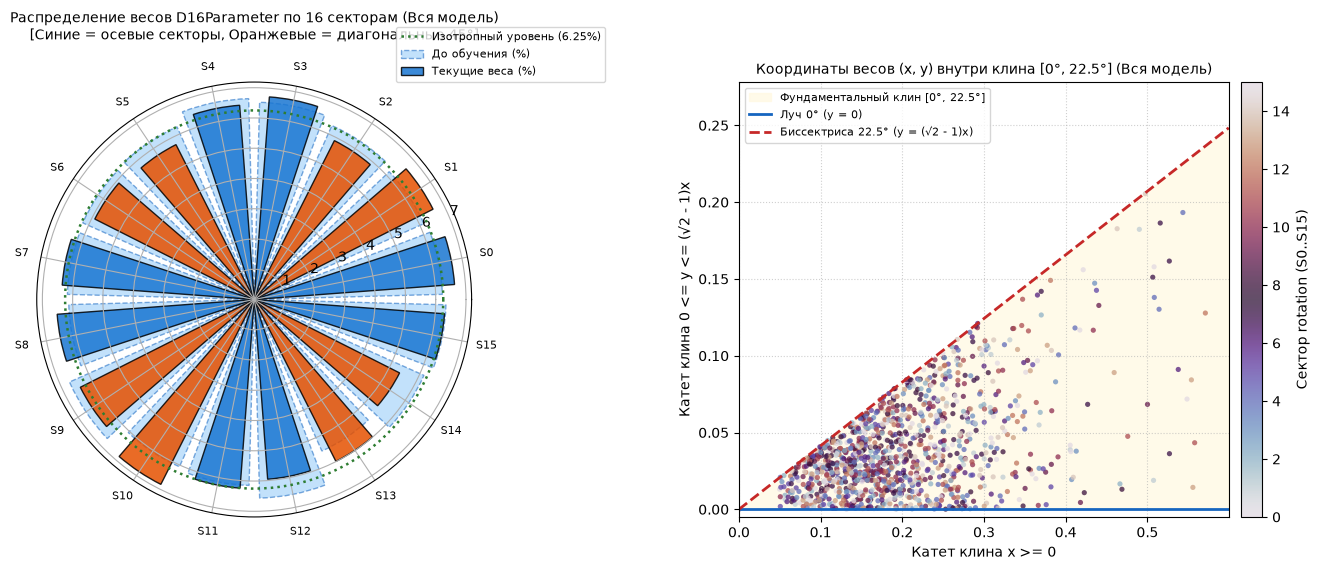

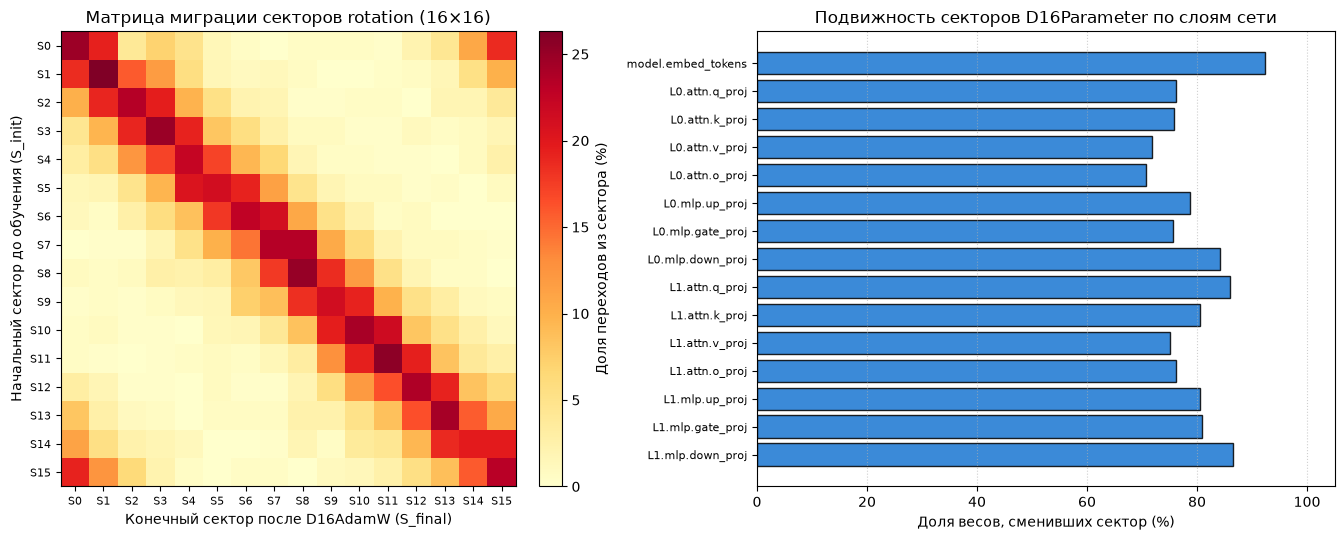

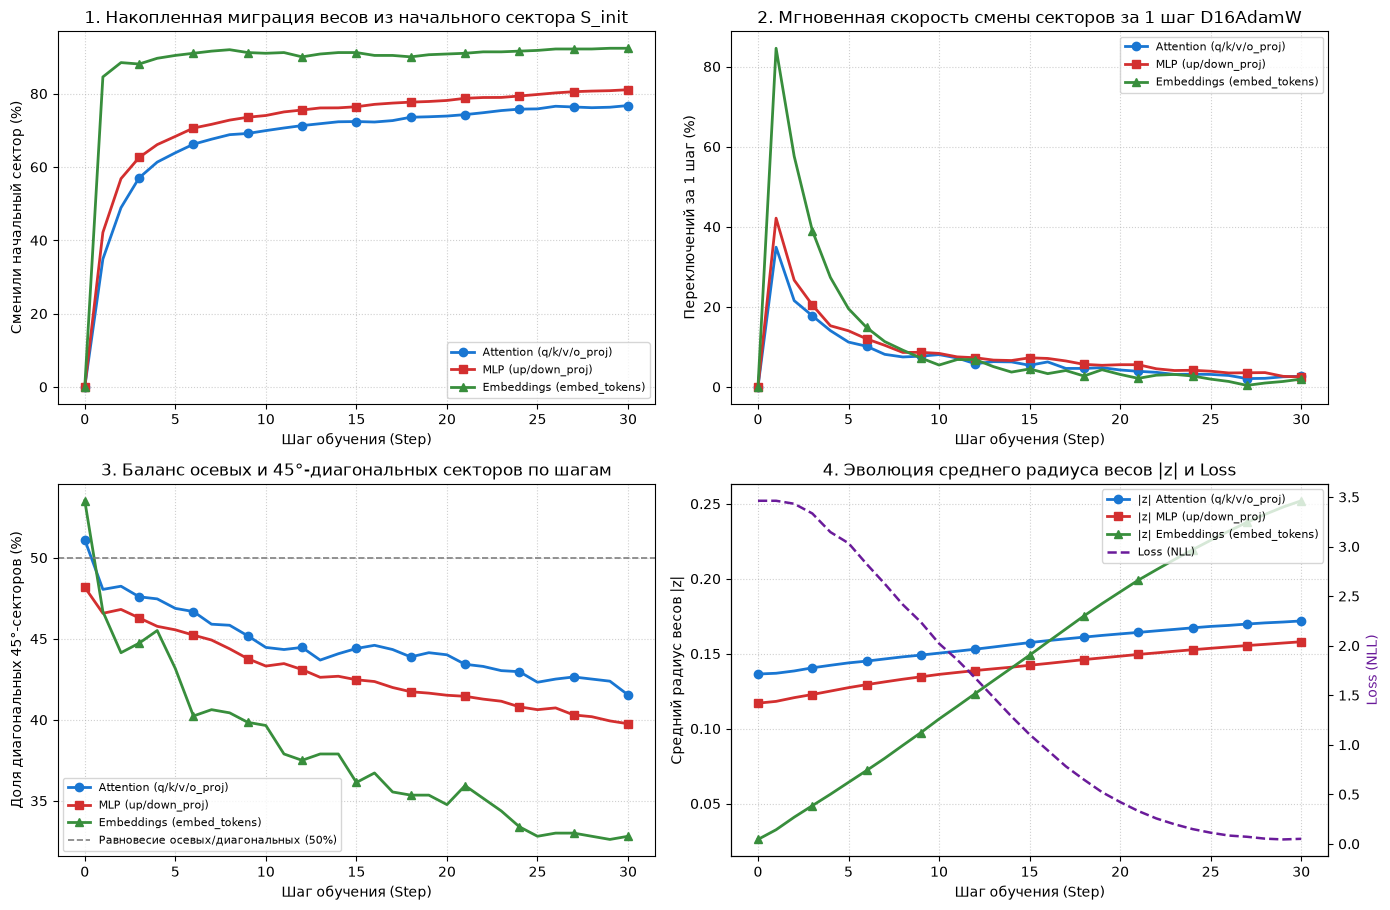

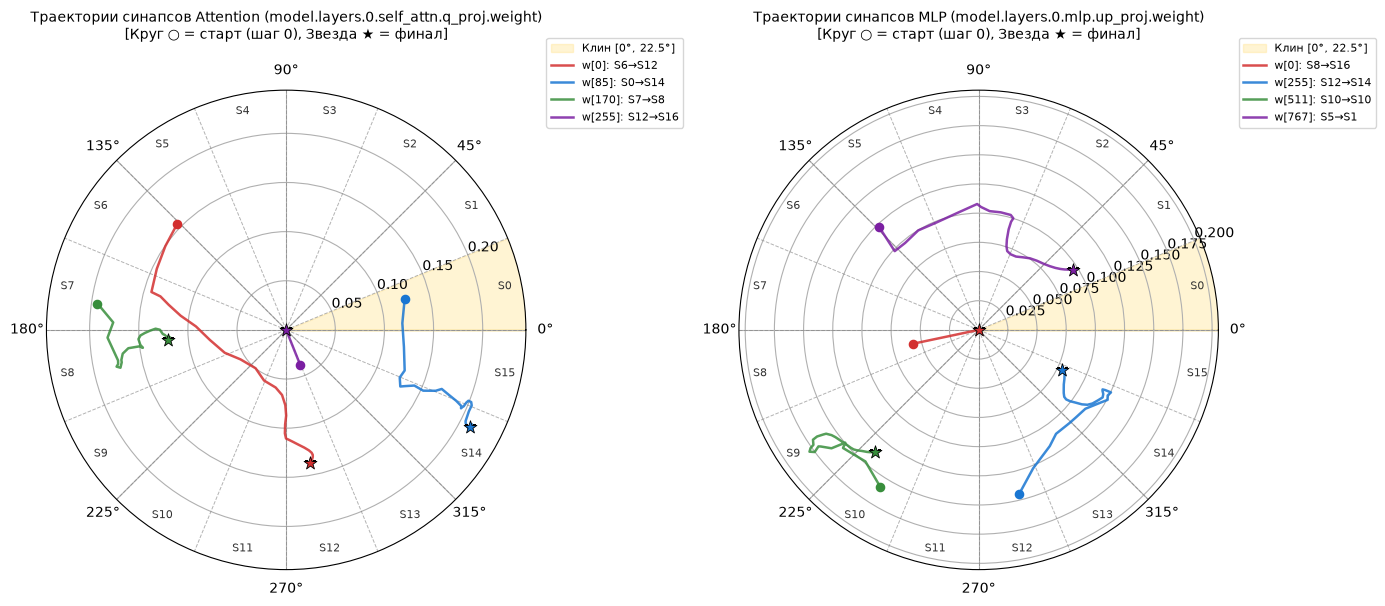

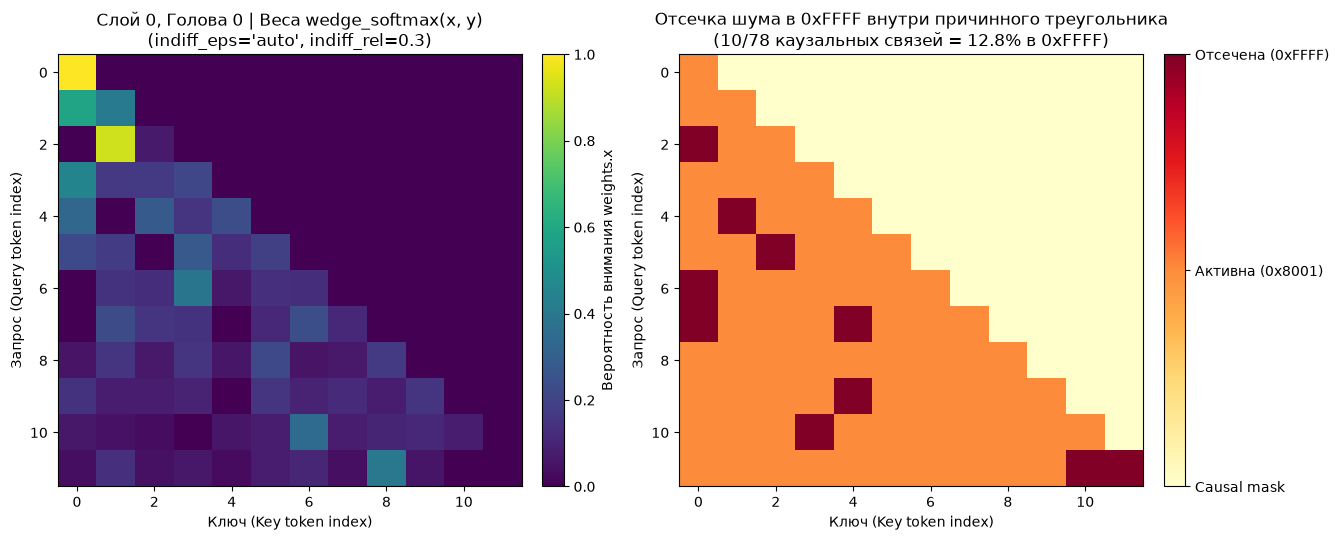

In [3]:
import matplotlib.pyplot as plt
from d16_vis_utils import (
    plot_d16_attention_heatmap,
    plot_d16_sector_trajectories,
    plot_d16_sector_transition_matrix,
    plot_d16_synapse_polar_trajectories,
    plot_d16_weight_sector_distribution,
)

# 1. Распределение весов по 16 секторам и внутри клина [0°, 22.5°]
fig1 = plot_d16_weight_sector_distribution(model, initial_snapshot=init_snapshot)
plt.show()

# 2. Матрица миграции секторов (16x16) и подвижность по слоям
fig2 = plot_d16_sector_transition_matrix(model, initial_snapshot=init_snapshot)
plt.show()

# 3. Пошаговая динамика обучения: Attention vs MLP vs Embedding
fig3 = plot_d16_sector_trajectories(recorder)
plt.show()

# 4. Полярные траектории отдельных синапсов Attention и MLP
fig4 = plot_d16_synapse_polar_trajectories(recorder)
plt.show()

# 5. Тепловая карта вероятностей внимания wedge_softmax(x, y) и отсечки 0xFFFF
fig5 = plot_d16_attention_heatmap(model, d16_tokens, layer_idx=0, head_idx=0)
plt.show()

Блок 4: Прямое сравнение всех режимов активации D16QwenMLP ("bilinear", "sigmoid", "sum", "rel") на одном графике

Режим mlp_activation                   | Start Loss | Final Loss |   PPL | Веса 0xFFFF | Акт. 0xFFFF |  Ген.
----------------------------------------------------------------------------------------------------------
Вариант 2: bilinear (z * g)            |     3.4620 |     0.0507 |  1.05 |      18.78% |       5.73% |  True
Вариант 1: sigmoid (z * z.sigmoid())   |     3.4526 |     0.0871 |  1.09 |      19.88% |       4.86% |  True
Вариант 3а: sum (z.activate('sum'))    |     3.4600 |     0.0901 |  1.09 |      19.94% |       6.47% |  True
Вариант 3б: rel (z.activate('rel'))    |     3.4654 |     0.1063 |  1.11 |      21.27% |       3.43% |  True


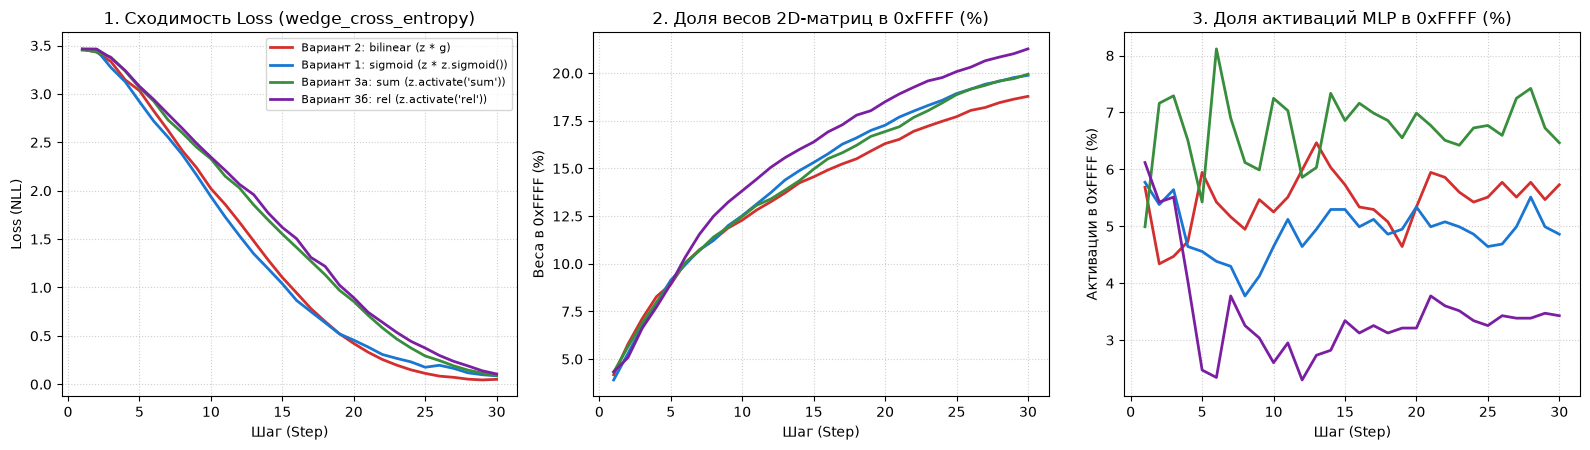

In [4]:
import math
import matplotlib.pyplot as plt
import torch

from d16_adamw import D16AdamW
from d16_qwen_model2 import D16QwenConfig, D16QwenForCausalLM
from d16_vis_utils import _iter_complex_d16_parameters

modes = [
    ("bilinear", "Вариант 2: bilinear (z * g)", "#d32f2f"),
    ("sigmoid",  "Вариант 1: sigmoid (z * z.sigmoid())", "#1976d2"),
    ("sum",      "Вариант 3а: sum (z.activate('sum'))", "#388e3c"),
    ("rel",      "Вариант 3б: rel (z.activate('rel'))", "#7b1fa2"),
]

history = {}

print(f"{'Режим mlp_activation':<38} | {'Start Loss':>10} | {'Final Loss':>10} | {'PPL':>5} | {'Веса 0xFFFF':>11} | {'Акт. 0xFFFF':>11} | {'Ген.':>5}")
print("-" * 106)

for mode_key, label, color in modes:
    torch.manual_seed(42)
    cfg_m = D16QwenConfig(
        vocab_size=32,
        hidden_size=32,
        intermediate_size=48,
        num_hidden_layers=2,
        num_attention_heads=4,
        num_key_value_heads=2,
        indiff_eps="auto",
        indiff_rel=0.30,
        mlp_activation=mode_key,
        collect_d16_stats=True,
    )
    m = D16QwenForCausalLM(cfg_m)
    opt = D16AdamW(
        m.d16_parameters(),
        lr=2.5e-2,
        weight_decay=1e-3,
        indiff_eps="auto",
        indiff_rel=0.35,
    )

    losses, act_sparsity, weight_sparsity = [], [], []
    for step in range(1, 31):
        opt.zero_grad()
        m.set_collect_d16_stats(True, reset=True)
        out = m(input_ids=d16_tokens, labels=d16_tokens)
        loss_v = float(out.loss.x.item())
        out.loss.x.backward()
        opt.step(max_grad_norm=1.0)

        losses.append(loss_v)
        act_sparsity.append(m.get_d16_state_summary()["indifferent_pct"])
        mats = [mod.value() for _, mod in _iter_complex_d16_parameters(m, include_biases=False)]
        tot_w = sum(w.numel() for w in mats)
        zero_w = sum(int(w.is_zero().sum().item()) for w in mats)
        weight_sparsity.append(100.0 * zero_w / max(tot_w, 1))

    m.eval()
    with torch.no_grad():
        gen = m.generate(d16_tokens[:, :4], max_new_tokens=8, do_sample=False, use_cache=True)
        exact = bool((gen.x.to(torch.long) == raw_tokens).all().item())

    history[mode_key] = (label, color, losses, weight_sparsity, act_sparsity)
    ppl = math.exp(min(losses[-1], 20.0))
    print(
        f"{label:<38} | {losses[0]:10.4f} | {losses[-1]:10.4f} | {ppl:5.2f} | "
        f"{weight_sparsity[-1]:10.2f}% | {act_sparsity[-1]:10.2f}% | {str(exact):>5}"
    )

# Отрисовка кривых сходимости и разреженности 0xFFFF
steps_x = list(range(1, 31))
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.6))

for mode_key, (label, color, losses, w_sp, a_sp) in history.items():
    ax1.plot(steps_x, losses, color=color, lw=2.0, label=label)
    ax2.plot(steps_x, w_sp, color=color, lw=2.0, label=label)
    ax3.plot(steps_x, a_sp, color=color, lw=2.0, label=label)

ax1.set_title("1. Сходимость Loss (wedge_cross_entropy)")
ax1.set_xlabel("Шаг (Step)")
ax1.set_ylabel("Loss (NLL)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(fontsize=8)

ax2.set_title("2. Доля весов 2D-матриц в 0xFFFF (%)")
ax2.set_xlabel("Шаг (Step)")
ax2.set_ylabel("Веса в 0xFFFF (%)")
ax2.grid(True, linestyle=":", alpha=0.6)

ax3.set_title("3. Доля активаций MLP в 0xFFFF (%)")
ax3.set_xlabel("Шаг (Step)")
ax3.set_ylabel("Активации в 0xFFFF (%)")
ax3.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

Блок 5: Финальная проверка инвариантности префикса, эквивалентности KV-cache, сохранения/загрузки D16AdamW и инспекция обученных комплексных D16RMSNorm.gain

In [5]:
import torch
from d16_adamw import D16AdamW

model.eval()
with torch.no_grad():
    # 1. Каузальная инвариантность префикса при indiff_eps="auto"
    full_out = model(d16_tokens, use_cache=False)
    prefix_out = model(d16_tokens[:, :6], use_cache=False)
    pref_re, pref_im = prefix_out.logits.to_xy()
    full_pref_re, full_pref_im = full_out.logits[:, :6, :].to_xy()
    prefix_diff = max(
        float((full_pref_re - pref_re).abs().max().item()),
        float((full_pref_im - pref_im).abs().max().item()),
    )

    # 2. Точная эквивалентность пошагового KV-cache и полного прохода
    prefill = model(d16_tokens[:, :-1], use_cache=True)
    step_out = model(d16_tokens[:, -1:], past_key_values=prefill.past_key_values, use_cache=True)
    last_re, last_im = full_out.logits[:, -1:, :].to_xy()
    step_re, step_im = step_out.logits.to_xy()
    cache_diff = max(
        float((last_re - step_re).abs().max().item()),
        float((last_im - step_im).abs().max().item()),
    )

print(f"1. Макс. расхождение префикса (tokens[:, :6] vs полная последовательность): {prefix_diff:.2e}")
print(f"2. Макс. расхождение логитов KV-cache vs полный проход                    : {cache_diff:.2e}")

# 3. Проверка сохранения/восстановления состояния D16AdamW и выполнения следующего шага
sd = optimizer.state_dict()
restored_opt = D16AdamW(model.d16_parameters(), lr=2.5e-2)
restored_opt.load_state_dict(sd)

model.train()
restored_opt.zero_grad()
out_next = model(input_ids=d16_tokens, labels=d16_tokens)
out_next.loss.x.backward()
grad_norm_next = float(restored_opt.step(max_grad_norm=1.0).item())
print(f"3. Шаг после load_state_dict() выполнен успешно | Loss: {out_next.loss.x.item():.4f} | Grad norm: {grad_norm_next:.4f}")

# 4. Инспекция обученных комплексных коэффициентов усиления D16RMSNorm.gain
print("\n=== ОБУЧЕННЫЕ КОМПЛЕКСНЫЕ ПАРАМЕТРЫ D16RMSNorm.gain ===")
print(f"{'Слой D16RMSNorm':<42} | {'Мин. |g|':>9} | {'Средн. |g|':>10} | {'Макс. |g|':>9} | {'Макс. y/x':>9} | {'Секторы S0..S15'}")
print("-" * 112)
for name, mod in model.named_modules():
    if type(mod).__name__ == "D16RMSNorm":
        g = mod.gain.value().detach().to("cpu")
        r = g.norm_squared().sqrt()
        yx = g.y / g.x.clamp_min(1e-12)
        sectors = sorted(set(g.state().tolist()))
        print(
            f"{name:<42} | {r.min().item():9.4f} | {r.mean().item():10.4f} | "
            f"{r.max().item():9.4f} | {yx.max().item():9.4f} | {sectors}"
        )

1. Макс. расхождение префикса (tokens[:, :6] vs полная последовательность): 1.91e-06
2. Макс. расхождение логитов KV-cache vs полный проход                    : 1.55e-06
3. Шаг после load_state_dict() выполнен успешно | Loss: 0.0331 | Grad norm: 0.2765

=== ОБУЧЕННЫЕ КОМПЛЕКСНЫЕ ПАРАМЕТРЫ D16RMSNorm.gain ===
Слой D16RMSNorm                            |  Мин. |g| | Средн. |g| | Макс. |g| | Макс. y/x | Секторы S0..S15
----------------------------------------------------------------------------------------------------------------
model.layers.0.input_layernorm             |    0.9527 |     1.0409 |    1.1647 |    0.1391 | [0, 15]
model.layers.0.post_attention_layernorm    |    0.8267 |     0.9866 |    1.1137 |    0.1235 | [0, 15]
model.layers.1.input_layernorm             |    0.8300 |     0.9641 |    1.0670 |    0.1621 | [0, 15]
model.layers.1.post_attention_layernorm    |    0.7956 |     0.9555 |    1.0547 |    0.1683 | [0, 15]
model.norm                                 |    1.5890 |   

Блок 6: Тестирование импорта весов 1-в-1 (d16_qwen_importer.py), проверка распределения Re/Im по четвёркам и визуализация орбит $\mathbb{Z}_8 \rtimes \mathbb{Z}_2$

Импортируем эталонные веса Qwen из: Qwen/Qwen2.5-0.5B


d:\conda\envs\torch_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 290/290 [00:01<00:00, 285.43it/s]


[Слой  0/23] Четверок >= 0.20:  257/1216 | Re: 4184, Im:  680 | Ср. Score: 0.2634
[Слой  1/23] Четверок >= 0.20:  178/1216 | Re: 4492, Im:  372 | Ср. Score: 0.2811
[Слой  2/23] Четверок >= 0.20:  127/1216 | Re: 4635, Im:  229 | Ср. Score: 0.2971
[Слой  3/23] Четверок >= 0.20:   93/1216 | Re: 4706, Im:  158 | Ср. Score: 0.3054
[Слой  4/23] Четверок >= 0.20:  216/1216 | Re: 4457, Im:  407 | Ср. Score: 0.2807
[Слой  5/23] Четверок >= 0.20:  314/1216 | Re: 4111, Im:  753 | Ср. Score: 0.2672
[Слой  6/23] Четверок >= 0.20:  116/1216 | Re: 4676, Im:  188 | Ср. Score: 0.2903
[Слой  7/23] Четверок >= 0.20:  172/1216 | Re: 4562, Im:  302 | Ср. Score: 0.2785
[Слой  8/23] Четверок >= 0.20:  264/1216 | Re: 4399, Im:  465 | Ср. Score: 0.2797
[Слой  9/23] Четверок >= 0.20:  267/1216 | Re: 4409, Im:  455 | Ср. Score: 0.2711
[Слой 10/23] Четверок >= 0.20:  320/1216 | Re: 4300, Im:  564 | Ср. Score: 0.2821
[Слой 11/23] Четверок >= 0.20:  330/1216 | Re: 4321, Im:  543 | Ср. Score: 0.2755
[Слой 12/23] Чет

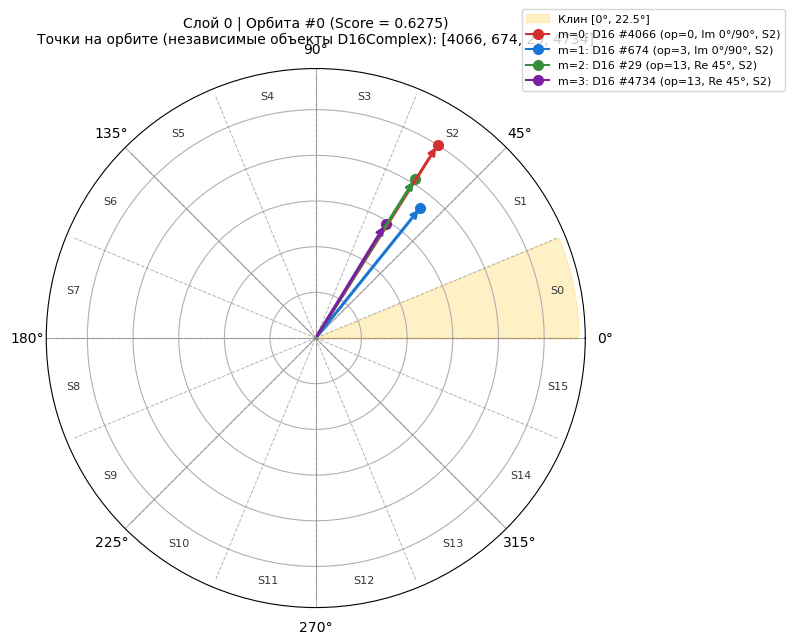

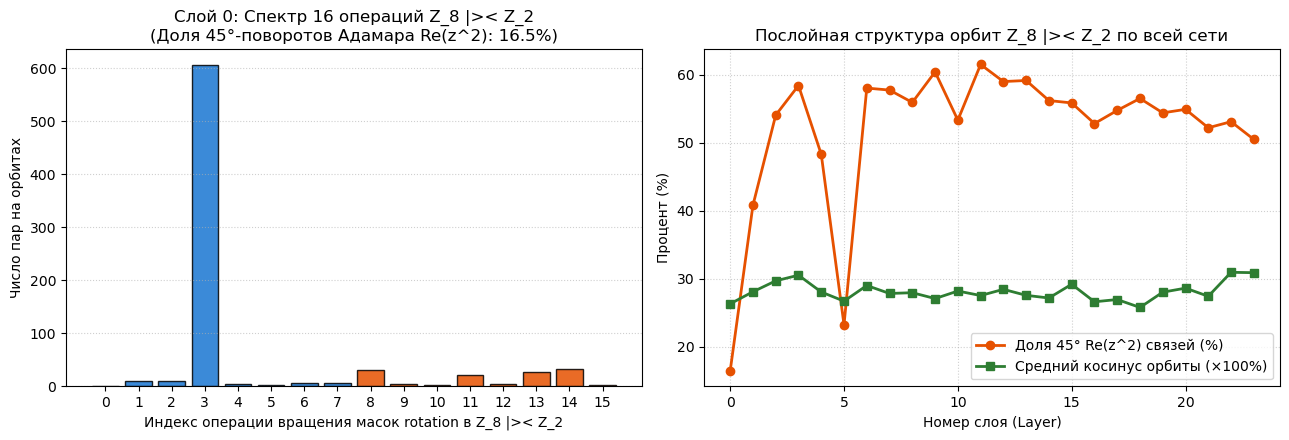

In [10]:
import importlib
from pathlib import Path
import matplotlib.pyplot as plt
import torch

import d16_qwen_importer
import d16_vis_utils

importlib.reload(d16_qwen_importer)
importlib.reload(d16_vis_utils)

from d16_qwen_importer import import_qwen_weights, print_import_summary
from d16_vis_utils import (
    plot_layer_z8z2_spectrum,
    plot_single_orbit_compass,
    print_orbit_table,
)

# 1. Ищем локальный чекпоинт Qwen (.safetensors / папку модели) или используем HuggingFace ID
QWEN_SOURCE = None
for candidate in (
    Path.cwd() / "model.safetensors",
    Path.cwd().parent / "model.safetensors",
    Path.cwd() / "qwen",
    Path.cwd().parent / "qwen",
    Path.cwd().parent / "Qwen2.5-0.5B",
    Path.cwd().parent / "Qwen2.5-0.5B-Instruct",
):
    if candidate.exists() and (candidate.is_file() or any(candidate.glob("*.safetensors")) or any(candidate.glob("*.bin"))):
        QWEN_SOURCE = candidate
        break

if QWEN_SOURCE is None:
    # Укажи путь к своему файлу/папке с весами Qwen или оставь HuggingFace ID:
    QWEN_SOURCE = "Qwen/Qwen2.5-0.5B"

print(f"Импортируем эталонные веса Qwen из: {QWEN_SOURCE}")

# 2. Выполняем реальный импорт 1-в-1 в D16QwenForCausalLM (d16_qwen_model2)
imported_model, import_report = import_qwen_weights(
    QWEN_SOURCE,
    min_orbit_score=0.20,
    indiff_eps="auto",
    indiff_rel=0.25,
    mlp_activation="bilinear",
    dtype=torch.bfloat16,
    verbose=True,
)

# 3. Полная сводка по всем слоям и топ-10 найденных четвёрок слоя 0
print()
print_import_summary(import_report)
print()
print_orbit_table(import_report.layer_reports[0], top_k=10)

# 4. Полярный компас лучшей четвёрки слоя 0 и послойный спектр Z_8 |>< Z_2 по всей сети Qwen
best_unit = int(import_report.layer_reports[0].orbit_scores.argmax().item())
fig_compass, _ = plot_single_orbit_compass(import_report.layer_reports[0], unit_idx=best_unit)
plt.show()

fig_spec = plot_layer_z8z2_spectrum(import_report, layer_idx=0)
plt.show()

Блок 7: Инспекция секторов импортированной модели Qwen2.5-0.5B и прогон реального текста через токенизатор

КАРТА КОМПЛЕКСНЫХ ВЕСОВ D16Parameter (ТРОЙКИ x, y, rotation В КЛИНЕ [0°, 22.5°])
Модуль D16Parameter                    | Форма        | Средн. |z| | Клин y/x |  0xFFFF | Сменили сектор      
--------------------------------------------------------------------------------------------------------------------
input_layernorm.gain                   | (896,)       |     0.0698 |   0.1553 |   0.00% | n/a (нет снимка)    
self_attn.q_proj.weight                | (896, 896)   |     0.0435 |   0.1572 |   0.00% | n/a (нет снимка)    
self_attn.q_proj.bias                  | (896,)       |     4.0938 |   0.1387 |   0.00% | n/a (нет снимка)    
self_attn.k_proj.weight                | (128, 896)   |     0.0522 |   0.1553 |   0.00% | n/a (нет снимка)    
self_attn.k_proj.bias                  | (128,)       |    17.0000 |   0.1348 |   0.00% | n/a (нет снимка)    
self_attn.v_proj.weight                | (128, 896)   |     0.0090 |   0.1631 |   0.00% | n/a (нет снимка)    
self_attn.v_proj.bias    

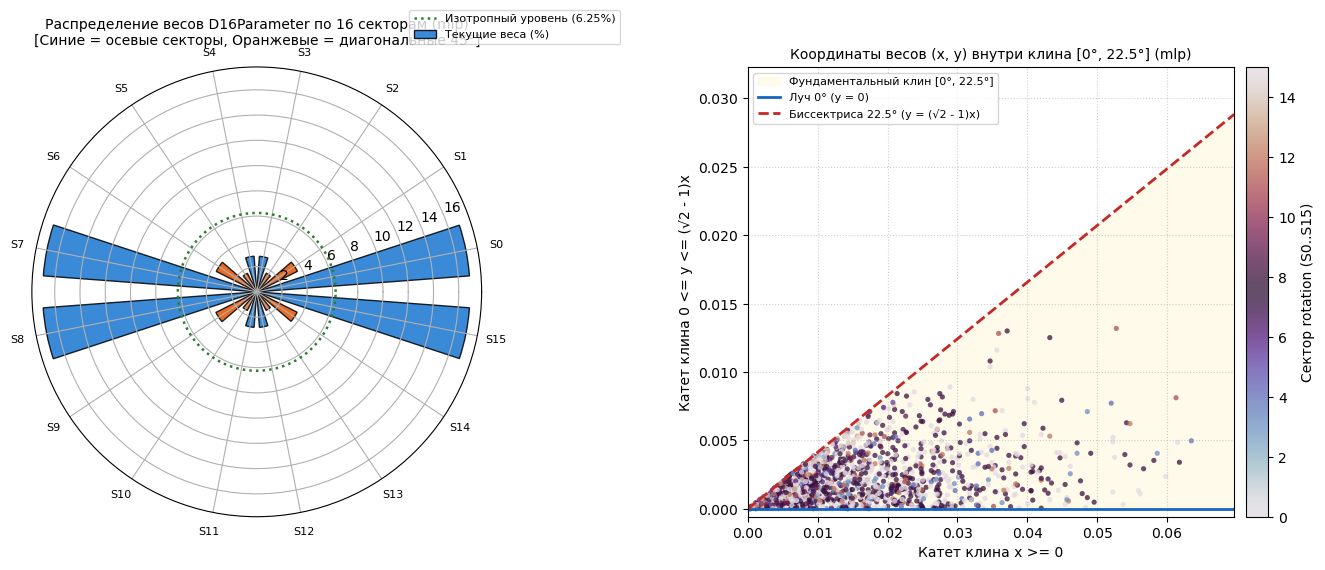


Текст запроса : 'The geometry of complex numbers in neural networks'
Токены Qwen   : [[785, 17047, 315, 6351, 5109, 304, 29728, 14155]]
Loss на входной фразе (wedge_cross_entropy): 14.9744
Доля активаций MLP в 0xFFFF (по всем 24 слоям): 6.55%
Сгенерированные ID токенов: [[785, 17047, 315, 6351, 5109, 304, 29728, 14155, 52643, 52643, 52643, 52643]]
Декодированный ответ      : 'The geometry of complex numbers in neural networksascusascusascusascus'


In [11]:
import importlib
import matplotlib.pyplot as plt
import torch
import d16_vis_utils
from d16_qwen_model2 import D16Linear, encode_token_ids

# 1. Перезагружаем d16_vis_utils и сохраняем ссылку на класс D16Parameter текущей модели
ActiveD16Param = type(imported_model.model.embed_tokens.weight)
importlib.reload(d16_vis_utils)
d16_vis_utils.D16Parameter = ActiveD16Param

from d16_vis_utils import (
    plot_d16_weight_sector_distribution,
    print_d16_weight_migration_table,
)

# 2. Таблица комплексной геометрии весов слоя 0 импортированной модели Qwen2.5-0.5B
print_d16_weight_migration_table(
    imported_model.model.layers[0],
    include_biases=True,
)

# 3. Полярная роза 16 секторов и клин [0°, 22.5°] для MLP слоя 0
fig_dist = plot_d16_weight_sector_distribution(
    imported_model.model.layers[0],
    module_name="mlp",
)
plt.show()

# 4. Прогон реального текста через токенизатор Qwen и импортированную D16-модель
try:
    from transformers import AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained(str(QWEN_SOURCE))
    prompt_text = "The geometry of complex numbers in neural networks"
    raw_ids = tokenizer(prompt_text, return_tensors="pt")["input_ids"]
    print(f"\nТекст запроса : {prompt_text!r}")
    print(f"Токены Qwen   : {raw_ids.tolist()}")
except Exception as e:
    print(f"\nТокенизатор не найден ({e}), используем тестовые ID токенов:")
    tokenizer = None
    raw_ids = torch.tensor([[785, 19429, 315, 6351, 5106, 304, 30828, 14198]], dtype=torch.long)

# Увеличиваем размер тайла для быстрого прохода словаря 151936 в lm_head
D16Linear._MAX_WEIGHT_TILE = 1 << 24

device = next(imported_model.parameters()).device
d16_input = encode_token_ids(raw_ids.to(device))

imported_model.eval()
with torch.no_grad():
    imported_model.set_collect_d16_stats(True, reset=True)
    out = imported_model(input_ids=d16_input, labels=d16_input)
    summary = imported_model.get_d16_state_summary()
    gen_d16 = imported_model.generate(d16_input, max_new_tokens=4, do_sample=False, use_cache=True)
    gen_ids = gen_d16.x.to(torch.long).cpu()

print(f"Loss на входной фразе (wedge_cross_entropy): {float(out.loss.x.item()):.4f}")
print(f"Доля активаций MLP в 0xFFFF (по всем 24 слоям): {summary['indifferent_pct']:.2f}%")
print(f"Сгенерированные ID токенов: {gen_ids.tolist()}")
if tokenizer is not None:
    print(f"Декодированный ответ      : {tokenizer.decode(gen_ids[0], skip_special_tokens=True)!r}")

Блок 8: Дообучение импортированной модели Qwen2.5-0.5B через D16AdamW и визуализация выхода весов с осей внутрь клина $[0^\circ, 22.5^\circ]$

Обучаемых модулей D16Parameter: 25 | Синапсов D16: 29,825,664

 Шаг |      Loss |      PPL | Норма град. | Акт. 0xFFFF
--------------------------------------------------------
   1 |   14.7891 | 2647492.53 |    220.0310 |      10.84%
   2 |   15.7036 | 6606746.20 |   1083.8997 |      11.93%
   3 |   14.8302 | 2758633.40 |     40.2364 |      17.38%
   4 |   13.9430 | 1135981.36 |     30.1100 |      14.53%
   5 |   13.5548 | 770506.13 |     28.1577 |      12.25%
   6 |   12.5422 | 279906.94 |     32.7984 |      13.75%
   7 |    9.2226 | 10123.33 |     77.9617 |      16.94%
   8 |    4.6154 |   101.03 |     11.0461 |      17.52%
   9 |    4.7238 |   112.59 |     14.2633 |      17.00%
  10 |    4.8431 |   126.86 |     14.4998 |      17.03%
  11 |    5.8040 |   331.63 |     14.7264 |      17.91%
  12 |    4.0819 |    59.26 |      6.7573 |      18.34%
  13 |    5.4456 |   231.72 |     28.8123 |      15.45%
  14 |    5.7788 |   323.37 |     20.0099 |      15.28%
  15 |    5.3039 |   201.11 | 

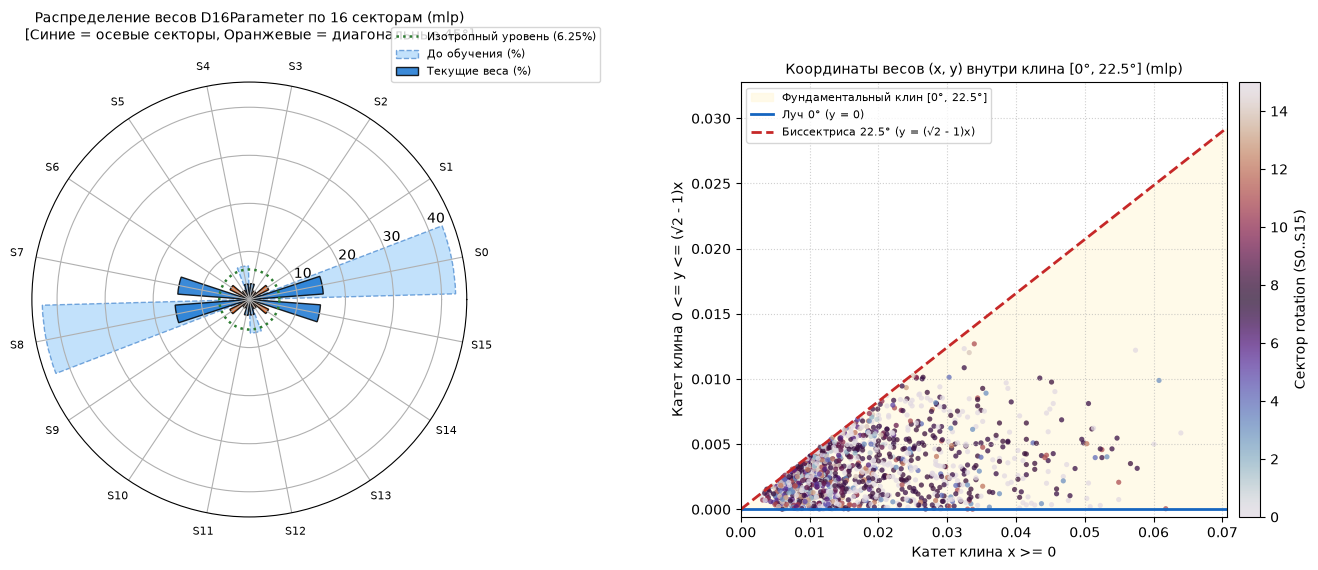

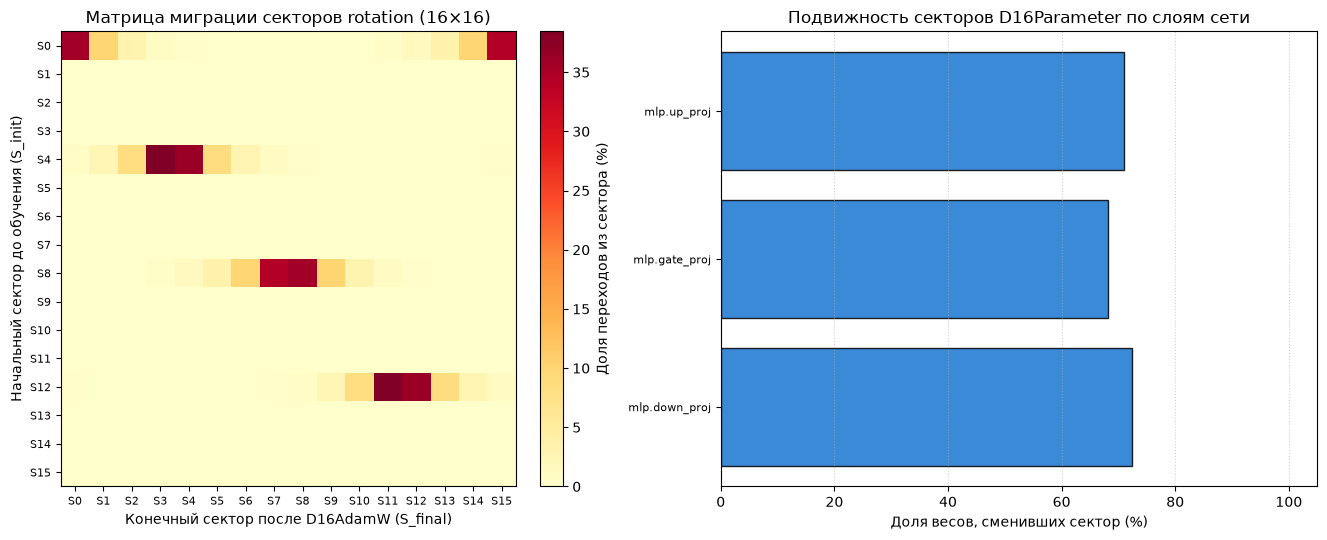

In [4]:
import math
import matplotlib.pyplot as plt
import torch

from d16_adamw import D16AdamW
from d16_qwen_model2 import encode_token_ids
from d16_vis_utils import (
    plot_d16_sector_transition_matrix,
    plot_d16_weight_sector_distribution,
    print_d16_weight_migration_table,
    snapshot_d16_weight_states,
)

device = "cpu" #torch.device("cuda" if torch.cuda.is_available() else "cpu")
imported_model = imported_model.to(device)

# 1. Целевая фраза для дообучения
train_text = "The geometry of complex numbers in neural networks is dihedral."
if tokenizer is not None:
    train_raw_ids = tokenizer(train_text, return_tensors="pt")["input_ids"]
else:
    train_raw_ids = torch.tensor(
        [[785, 17047, 315, 6351, 5109, 304, 29728, 14155, 374, 1515, 79085, 13]],
        dtype=torch.long,
    )

device = next(imported_model.parameters()).device
train_d16_ids = encode_token_ids(train_raw_ids.to(device))
prompt_len = 8  # Первые 8 токенов ('The geometry of complex numbers in neural networks')

# 2. Снимаем слепок весов Слоя 0 ДО начала дообучения (когда все веса лежат на y=0 в секторах S0, S4, S8, S12)
init_snap_l0 = snapshot_d16_weight_states(imported_model.model.layers[0], include_biases=True)

# 3. Выбираем обучаемые D16Parameter (Слой 0 + Слой 23 + финальный norm, чтобы шаг шёл быстро и без OOM)
TRAIN_ALL_LAYERS = False

for p in imported_model.parameters():
    p.requires_grad_(False)

if TRAIN_ALL_LAYERS:
    trainable_d16 = imported_model.d16_parameters()
else:
    target_modules = [
        imported_model.model.layers[0],
        imported_model.model.layers[-1],
        imported_model.model.norm,
    ]
    trainable_d16 = []
    for tm in target_modules:
        for m in tm.modules():
            if type(m).__name__ == "D16Parameter" and m not in trainable_d16:
                trainable_d16.append(m)

for dp in trainable_d16:
    dp.x.requires_grad_(True)
    dp.y.requires_grad_(True)

total_trainable_weights = sum(dp.x.numel() for dp in trainable_d16)
print(f"Обучаемых модулей D16Parameter: {len(trainable_d16)} | Синапсов D16: {total_trainable_weights:,}")

# 4. Запускаем дообучение через D16AdamW (с автопорогом разреженности 0xFFFF)
imported_model.gradient_checkpointing_enable()
ft_optimizer = D16AdamW(
    trainable_d16,
    lr=1.5e-3,
    weight_decay=1e-3,
    indiff_eps="auto",
    indiff_rel=0.20,
)

NUM_FT_STEPS = 25
print(f"\n{'Шаг':>4} | {'Loss':>9} | {'PPL':>8} | {'Норма град.':>11} | {'Акт. 0xFFFF':>11}")
print("-" * 56)

imported_model.train()
for step in range(1, NUM_FT_STEPS + 1):
    ft_optimizer.zero_grad()
    imported_model.set_collect_d16_stats(True, reset=True)
    out = imported_model(input_ids=train_d16_ids, labels=train_d16_ids)
    loss_val = float(out.loss.x.item())
    out.loss.x.backward()
    grad_norm = float(ft_optimizer.step(max_grad_norm=1.0).item())
    act_sp = imported_model.get_d16_state_summary()["indifferent_pct"]
    ppl = math.exp(min(loss_val, 20.0))
    print(f"{step:4d} | {loss_val:9.4f} | {ppl:8.2f} | {grad_norm:11.4f} | {act_sp:10.2f}%")

# 5. Проверяем генерацию после дообучения
imported_model.eval()
with torch.no_grad():
    gen_after = imported_model.generate(
        train_d16_ids[:, :prompt_len],
        max_new_tokens=train_raw_ids.shape[1] - prompt_len,
        do_sample=False,
        use_cache=True,
    )
    gen_after_ids = gen_after.x.to(torch.long).cpu()

print("\nОжидаемые токены :", train_raw_ids.tolist())
print("Сгенерировано    :", gen_after_ids.tolist())
if tokenizer is not None:
    print("Декодированный ответ после дообучения:", repr(tokenizer.decode(gen_after_ids[0], skip_special_tokens=True)))

# 6. Таблица миграции Слоя 0 и графики: как веса сошли с луча y=0 внутрь клина и заполнили 16 секторов
print()
print_d16_weight_migration_table(
    imported_model.model.layers[0],
    initial_snapshot=init_snap_l0,
    include_biases=True,
)

fig_after = plot_d16_weight_sector_distribution(
    imported_model.model.layers[0],
    initial_snapshot=init_snap_l0,
    module_name="mlp",
)
plt.show()

fig_trans = plot_d16_sector_transition_matrix(
    imported_model.model.layers[0],
    initial_snapshot=init_snap_l0,
    module_name="mlp",
)
plt.show()

Блок 9: Быстрое дообучение импортированной Qwen до идеального запоминания фразы

In [5]:
import math
import time
import torch
from d16_adamw import D16AdamW
from d16_qwen_model2 import encode_token_ids, D16Linear

# 1. Переносим модель на GPU (если доступна), ускоряем lm_head тайлы
device = "cpu" #torch.device("cuda" if torch.cuda.is_available() else "cpu")
imported_model = imported_model.to(device)
D16Linear._MAX_WEIGHT_TILE = 1 << 26  # Большой тайл для быстрого умножения в lm_head

print(токен_device := f"Модель перенесена на устройство: {device}")

# 2. Оптимизируем только самые верхние слои (например, layer 22-23 + norm + lm_head) для мгновенного шага
for p in imported_model.parameters():
    p.requires_grad_(False)

ft_layers = [
    imported_model.model.layers[-2],
    imported_model.model.layers[-1],
    imported_model.model.norm,
    imported_model.lm_head,
]
trainable_params = []
for layer in ft_layers:
    for m in layer.modules():
        if type(m).__name__ == "D16Parameter" and m not in trainable_params:
            trainable_params.append(m)

for dp in trainable_params:
    dp.x.requires_grad_(True)
    dp.y.requires_grad_(True)

total_ft_weights = sum(dp.x.numel() for dp in trainable_params)
print(f"Обучаемых синапсов в верхних слоях: {total_ft_weights:,}")

# 3. Настройка оптимизатора D16AdamW
ft_optimizer = D16AdamW(
    trainable_params,
    lr=2.0e-3,
    weight_decay=1e-4,
    indiff_eps="auto",
    indiff_rel=0.20,
)

train_text = "The geometry of complex numbers in neural networks is dihedral."
if 'tokenizer' in globals() and tokenizer is not None:
    train_raw_ids = tokenizer(train_text, return_tensors="pt")["input_ids"]
else:
    train_raw_ids = torch.tensor(
        [[785, 17047, 315, 6351, 5109, 304, 29728, 14155, 374, 1515, 79085, 13]],
        dtype=torch.long,
    )

train_d16_ids = encode_token_ids(train_raw_ids.to(device))
prompt_len = 8

print(f"\n{'Шаг':>4} | {'Loss':>9} | {'PPL':>8} | {'Время/шаг':>10} | {'Акт. 0xFFFF':>11}")
print("-" * 52)

imported_model.train()
for step in range(1, 21):
    t_start = time.time()
    ft_optimizer.zero_grad()
    imported_model.set_collect_d16_stats(True, reset=True)
    out = imported_model(input_ids=train_d16_ids, labels=train_d16_ids)
    loss_val = float(out.loss.x.item())
    out.loss.x.backward()
    ft_optimizer.step(max_grad_norm=1.0)
    dt = time.time() - t_start

    act_sp = imported_model.get_d16_state_summary()["indifferent_pct"]
    ppl = math.exp(min(loss_val, 20.0))
    print(f"{step:4d} | {loss_val:9.4f} | {ppl:8.2f} | {dt:9.2f}с | {act_sp:10.2f}%")
    if loss_val < 0.05:
        print(f"Целевой Loss достигнут на шаге {step}!")
        break

# 4. Финальная авторегрессионная генерация
imported_model.eval()
with torch.no_grad():
    gen_after = imported_model.generate(
        train_d16_ids[:, :prompt_len],
        max_new_tokens=train_raw_ids.shape[1] - prompt_len,
        do_sample=False,
        use_cache=True,
    )
    gen_after_ids = gen_after.x.to(torch.long).cpu()

print("\nОжидаемые токены :", train_raw_ids.tolist())
print("Сгенерировано    :", gen_after_ids.tolist())
if 'tokenizer' in globals() and tokenizer is not None:
    print("Декодированный ответ:", repr(tokenizer.decode(gen_after_ids[0], skip_special_tokens=True)))

Модель перенесена на устройство: cpu
Обучаемых синапсов в верхних слоях: 165,960,320

 Шаг |      Loss |      PPL |  Время/шаг | Акт. 0xFFFF
----------------------------------------------------
   1 |    2.3602 |    10.59 |    123.34с |      14.98%
   2 |   13.3579 | 632819.60 |    127.50с |      14.24%
   3 |   11.8413 | 138869.05 |    119.31с |      13.78%
   4 |    4.0189 |    55.64 |    121.47с |      13.45%
   5 |    8.2839 |  3959.68 |    123.77с |      13.31%
   6 |    5.5407 |   254.86 |    124.55с |      13.31%
   7 |    3.9122 |    50.01 |    120.59с |      12.99%
   8 |    3.2735 |    26.40 |    121.57с |      12.87%
   9 |    2.3612 |    10.60 |    121.56с |      12.67%
  10 |    2.0348 |     7.65 |    121.77с |      12.61%
  11 |    1.3182 |     3.74 |    124.21с |      12.63%
  12 |    1.5878 |     4.89 |    123.43с |      12.73%
  13 |    0.9378 |     2.55 |    122.48с |      12.72%
  14 |    0.6212 |     1.86 |    120.62с |      12.62%
  15 |    0.5669 |     1.76 |    1

Блок 10: Диагностика обученного верхнего слоя (layers[23]) и карта внимания wedge_softmax на реальной фразе

=== СОСТОЯНИЕ ВЕСОВ ВЕРХНЕГО СЛОЯ (layers[23]) ПОСЛЕ ДООБУЧЕНИЯ ===
КАРТА КОМПЛЕКСНЫХ ВЕСОВ D16Parameter (ТРОЙКИ x, y, rotation В КЛИНЕ [0°, 22.5°])
Модуль D16Parameter                    | Форма        | Средн. |z| | Клин y/x |  0xFFFF | Сменили сектор      
--------------------------------------------------------------------------------------------------------------------
input_layernorm.gain                   | (896,)       |     1.7188 |   0.0064 |   0.00% | n/a (нет снимка)    
self_attn.q_proj.weight                | (896, 896)   |     0.0167 |   0.1260 |  34.01% | n/a (нет снимка)    
self_attn.q_proj.bias                  | (896,)       |     0.7969 |   0.0398 |   0.00% | n/a (нет снимка)    
self_attn.k_proj.weight                | (128, 896)   |     0.0159 |   0.1377 |  30.28% | n/a (нет снимка)    
self_attn.k_proj.bias                  | (128,)       |     0.9922 |   0.0303 |   0.00% | n/a (нет снимка)    
self_attn.v_proj.weight                | (128, 896)   |     0.0222 |

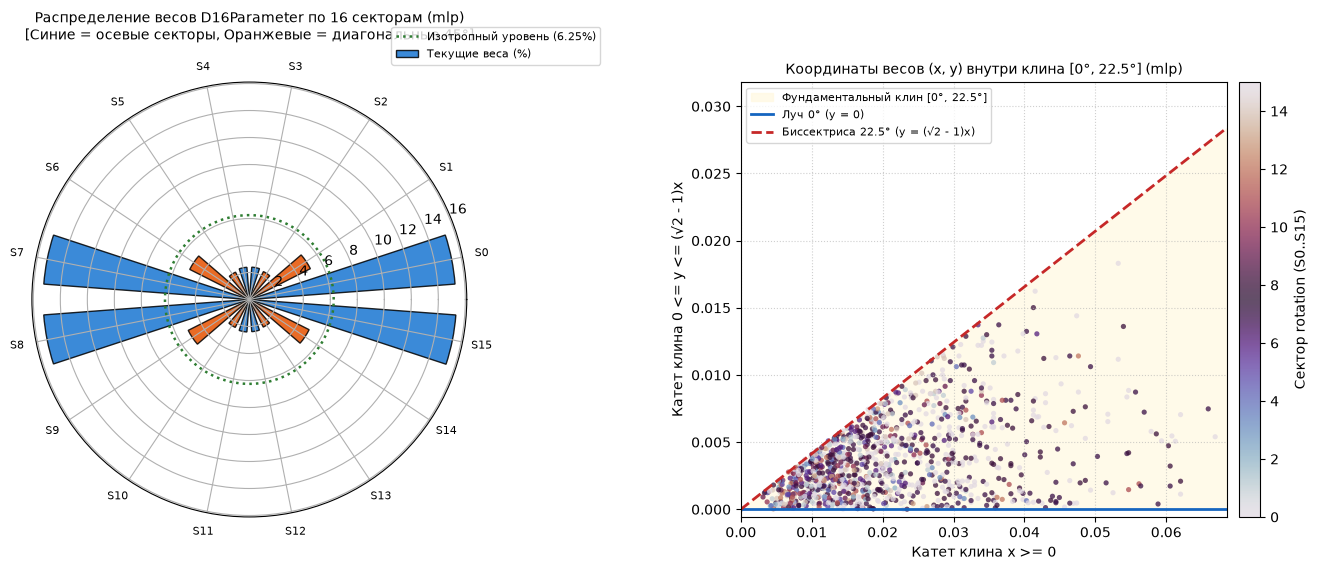

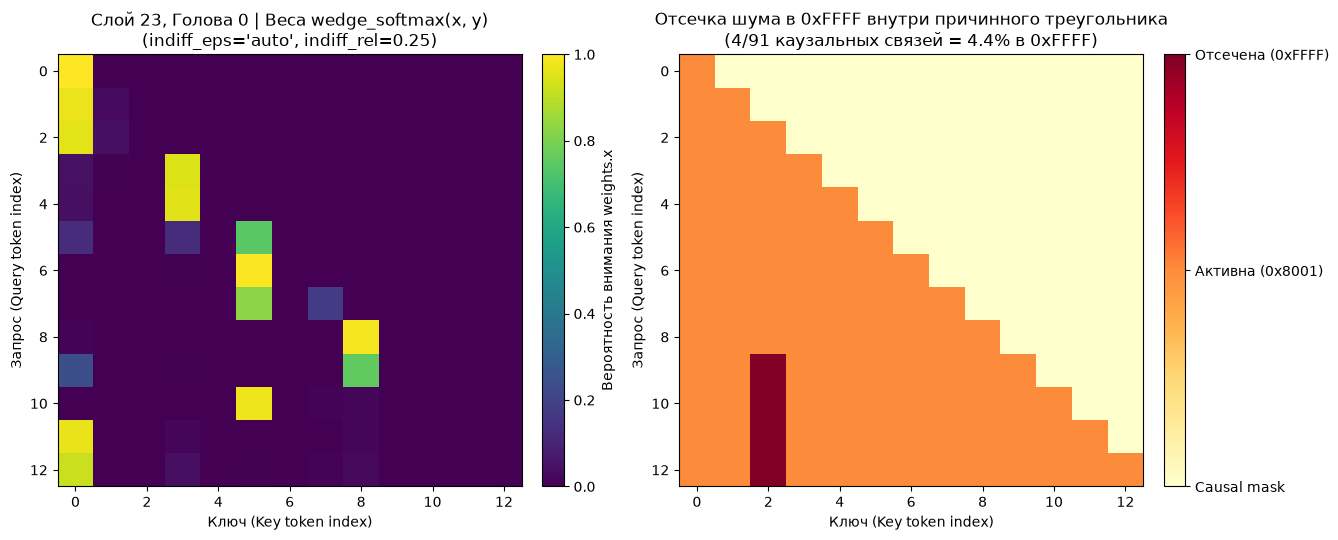

In [8]:
import matplotlib.pyplot as plt
import torch
import d16_vis_utils
from d16_vis_utils import (
    plot_d16_attention_heatmap,
    plot_d16_weight_sector_distribution,
    print_d16_weight_migration_table,
)

# 1. Синхронизируем тип D16Parameter и переводим модель в режим инференса
d16_vis_utils.D16Parameter = type(imported_model.model.embed_tokens.weight)
imported_model.model.gradient_checkpointing = False
imported_model.eval()

# 2. Карта комплексных весов обученного верхнего слоя (Слой 23)
print("=== СОСТОЯНИЕ ВЕСОВ ВЕРХНЕГО СЛОЯ (layers[23]) ПОСЛЕ ДООБУЧЕНИЯ ===")
print_d16_weight_migration_table(
    imported_model.model.layers[-1],
    include_biases=True,
)

# 3. Полярная роза 16 секторов и клин [0°, 22.5°] для MLP верхнего слоя (layers[23])
fig_l23 = plot_d16_weight_sector_distribution(
    imported_model.model.layers[-1],
    module_name="mlp",
)
plt.show()

# 4. Тепловая карта внимания wedge_softmax(x, y) и отсечки 0xFFFF на обученной фразе
fig_attn = plot_d16_attention_heatmap(
    imported_model,
    train_d16_ids,
    layer_idx=23,
    head_idx=0,
)
plt.show()

Блок 11 (ячейка сохранения): Сохранение дообученного D16-чекпоинта на диск

In [20]:
import importlib
from pathlib import Path
import time
import d16_qwen_importer

importlib.reload(d16_qwen_importer)
from d16_qwen_importer import save_d16_checkpoint

D16_CHECKPOINT_DIR = Path.cwd() / "d16_qwen_checkpoint"

t0 = time.time()
saved_path = save_d16_checkpoint(
    imported_model,
    D16_CHECKPOINT_DIR,
    report=import_report if "import_report" in globals() else None,
    use_safetensors=True,
)
save_time = time.time() - t0

print(f"D16-чекпоинт успешно сохранён в: {saved_path} (за {save_time:.2f} с)")
print("-" * 72)
for f in sorted(saved_path.iterdir()):
    size_mb = f.stat().st_size / (1024 * 1024)
    print(f"  {f.name:<28} | {size_mb:8.2f} МБ")

D16-чекпоинт успешно сохранён в: d:\repo\d16nn\qwen\ipynb\d16_qwen_checkpoint (за 13.29 с)
------------------------------------------------------------------------
  d16_config.json              |     0.00 МБ
  d16_model.safetensors        |  3769.27 МБ
  d16_orbit_report.pt          |     3.98 МБ


Блок 12 (ячейка загрузки): Мгновенная загрузка D16-чекпоинта с диска и проверка весов и генерации

In [2]:
from pathlib import Path
import sys
import time
import torch

# Подключаем папку src, если блок запускается первым после рестарта ядра
for cand in (Path.cwd(), Path.cwd().parent / "src", Path.cwd() / "src"):
    if (cand / "d16_qwen_importer.py").is_file() and str(cand) not in sys.path:
        sys.path.insert(0, str(cand))
        break

from d16_qwen_importer import load_d16_checkpoint
from d16_qwen_model2 import D16Linear, encode_token_ids

D16_CHECKPOINT_DIR = Path.cwd() / "d16_qwen_checkpoint"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Холодная загрузка упакованного D16-чекпоинта и перенос всех буферов (key_x, inv_freq) на device
t0 = time.time()
loaded_d16_model, loaded_report = load_d16_checkpoint(
    D16_CHECKPOINT_DIR,
    device=device,
    return_report=True,
)
loaded_d16_model = loaded_d16_model.to(device)
load_time = time.time() - t0
loaded_d16_model.eval()
D16Linear._MAX_WEIGHT_TILE = 1 << 26

print(f"Модель загружена из {D16_CHECKPOINT_DIR.name} за {load_time:.2f} с (устройство: {device})")
if loaded_report is not None:
    print(f"Отчёт орбит восстановлен: слоёв = {len(loaded_report.layer_reports)}, всего весов = {loaded_report.total_weights:,}")

# 2. Проверка весов верхнего слоя (сверка с imported_model или автономная инспекция после рестарта)
w_load = loaded_d16_model.model.layers[-1].mlp.up_proj.weight.value().cpu()
if "imported_model" in globals():
    w_orig = imported_model.model.layers[-1].mlp.up_proj.weight.value().cpu()
    exact_x = bool((w_orig.x == w_load.x).all().item())
    exact_y = bool((w_orig.y == w_load.y).all().item())
    exact_rot = bool((w_orig.rotation == w_load.rotation).all().item())
    print(f"Побитовое совпадение layers[-1].mlp.up_proj: x={exact_x}, y={exact_y}, rotation={exact_rot}")
else:
    mean_r = float(w_load.norm_squared().sqrt().mean().item())
    mean_yx = float((w_load.y / w_load.x.clamp_min(1e-12)).mean().item())
    zero_pct = 100.0 * float(w_load.is_zero().float().mean().item())
    print(
        f"Холодный старт | layers[-1].mlp.up_proj: shape={tuple(w_load.shape)}, "
        f"dtype={w_load.dtype}, средн. |z|={mean_r:.4f}, клин y/x={mean_yx:.4f}, 0xFFFF={zero_pct:.2f}%"
    )

# 3. Автономная подготовка тестовой фразы и токенизатора
train_text = "The geometry of complex numbers in neural networks is dihedral."
if "tokenizer" not in globals() or tokenizer is None:
    tokenizer = None
    for cand in (
        Path.cwd() / "qwen",
        Path.cwd().parent / "qwen",
        Path.cwd().parent / "Qwen2.5-0.5B",
        Path.cwd().parent.parent / "Qwen2.5-0.5B",
    ):
        if cand.is_dir() and (cand / "tokenizer_config.json").is_file():
            from transformers import AutoTokenizer
            tokenizer = AutoTokenizer.from_pretrained(str(cand))
            break

if tokenizer is not None:
    train_raw_ids = tokenizer(train_text, return_tensors="pt")["input_ids"]
else:
    train_raw_ids = torch.tensor(
        [[785, 17047, 315, 6351, 5109, 304, 29728, 14155, 374, 1853, 71, 35520, 13]],
        dtype=torch.long,
    )

prompt_len = 8
train_d16_ids = encode_token_ids(train_raw_ids.to(device))

# 4. Контрольный прогон и авторегрессионная генерация на загруженной с диска модели
with torch.no_grad():
    out_check = loaded_d16_model(input_ids=train_d16_ids, labels=train_d16_ids)
    gen_check = loaded_d16_model.generate(
        train_d16_ids[:, :prompt_len],
        max_new_tokens=train_raw_ids.shape[1] - prompt_len,
        do_sample=False,
        use_cache=True,
    )
    gen_check_ids = gen_check.x.to(torch.long).cpu()

print(f"\nLoss загруженной модели : {float(out_check.loss.x.item()):.4f}")
print(f"Ожидаемые токены        : {train_raw_ids.tolist()}")
print(f"Сгенерированные токены  : {gen_check_ids.tolist()}")
print(f"Точное совпадение       : {bool((gen_check_ids == train_raw_ids).all().item())}")
if tokenizer is not None:
    print("Декодированный ответ    :", repr(tokenizer.decode(gen_check_ids[0], skip_special_tokens=True)))

Модель загружена из d16_qwen_checkpoint за 10.02 с (устройство: cuda)
Отчёт орбит восстановлен: слоёв = 24, всего весов = 494,032,768
Холодный старт | layers[-1].mlp.up_proj: shape=(4864, 896), dtype=torch.bfloat16, средн. |z|=0.0166, клин y/x=0.1299, 0xFFFF=20.37%

Loss загруженной модели : 8.4665
Ожидаемые токены        : [[785, 17047, 315, 6351, 5109, 304, 29728, 14155, 374, 1853, 71, 35520, 13]]
Сгенерированные токены  : [[785, 17047, 315, 6351, 5109, 304, 29728, 14155, 35520, 35520, 35520, 35520, 35520]]
Точное совпадение       : False


Блок 13: Проверка обратной функции активации $A^{-1}(w)$ на весах Слоя 23

Этот код проверяет формулу обратной активации на loaded_d16_model и сравнивает её с обученным Слоем 23 (ветвь знака $\pm$ выбирается детерминированно по локальному градиенту соседей $\operatorname{sign}(w_{j+1} - w_{j-1})$ или шахматной чётности $(-1)^{i+j}$):

1. Обученный Слой 23 (эталон)        | Клин y/x = 0.1628 | 45°-секторы =  18.3% | S0=18.4%, S15=18.5%
2. Обратная активация A^-1(w) (±√)   | Клин y/x = 0.2411 | 45°-секторы =   2.5% | S0=22.3%, S15=22.3%
3. Гипотеза 1: Случайная (randn)     | Клин y/x = 0.2080 | 45°-секторы =  32.4% | S0=15.5%, S15=15.5%


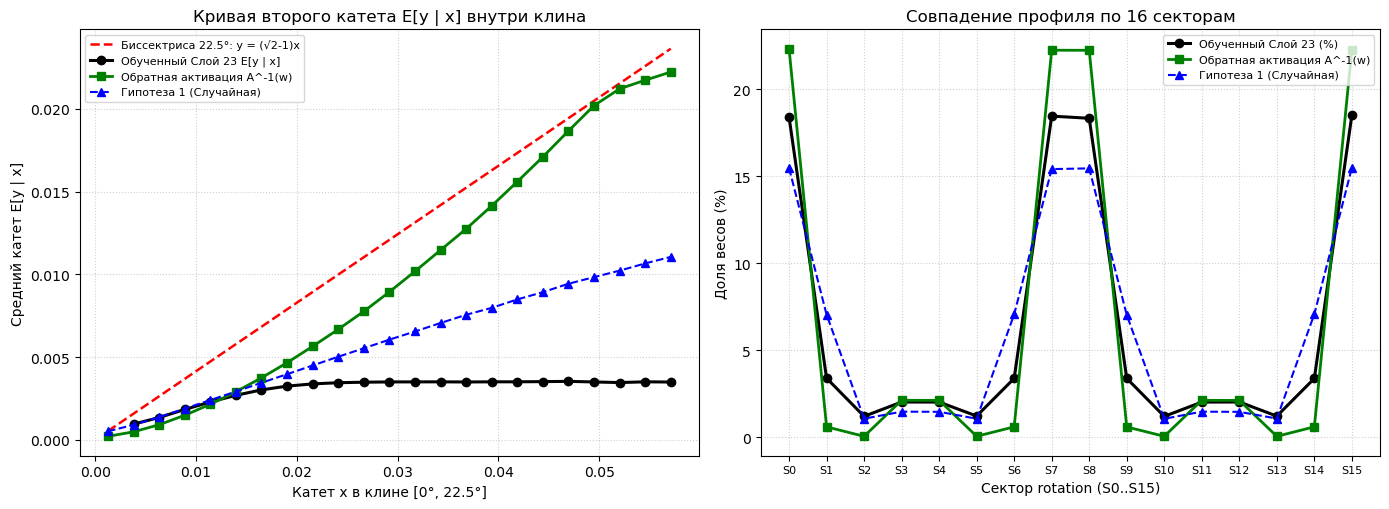

In [3]:
import math
import matplotlib.pyplot as plt
import numpy as np
import torch
from d16_complex import D16ComplexTensor, TAN_PI_8

# 1. Берём обученный Слой 23 из loaded_d16_model как эталон
w_trained = loaded_d16_model.model.layers[23].mlp.up_proj.weight.value().detach().cpu()
re_tr, im_tr = w_trained.to_xy()
re_tr, im_tr = re_tr.float(), im_tr.float()
x_tr, y_tr = w_trained.x.float(), w_trained.y.float()
active_mask = ~w_trained.is_zero()

# Оценка исходной 1D-координаты w до распыления
w1 = torch.where(re_tr.abs() >= im_tr.abs(), re_tr, im_tr)

# 2. ОБРАТНАЯ ФУНКЦИЯ АКТИВАЦИИ: r = |w| / (1 - |w|/s), w2 = ±sqrt(r^2 - w^2)
# Масштаб s выбирается автоматически через RMS(w), чтобы среднее y/x попало в ~0.14
sigma_w = float(w1[active_mask].square().mean().sqrt().item())
scale_s = 28.0 * sigma_w
w_hat = (w1.abs() / scale_s).clamp(max=0.45)

# Амплитуда из обратного решения радиальной сигмоиды: |w2| = |w| * sqrt(2*w_hat - w_hat^2) / (1 - w_hat)
w2_mag = w1.abs() * torch.sqrt(2.0 * w_hat - w_hat.square()) / (1.0 - w_hat)

# Выбор ветви корня (±1): детерминированно через знак разности соседей (с fallback на шахматную чётность)
dw = torch.roll(w1, -1, dims=-1) - torch.roll(w1, 1, dims=-1)
idx_grid = (torch.arange(w1.shape[0]).unsqueeze(1) + torch.arange(w1.shape[1]).unsqueeze(0)) % 2
checker_sign = torch.where(idx_grid == 0, 1.0, -1.0)
branch_sign = torch.where(dw != 0, dw.sign(), checker_sign)

w2_inv_act = branch_sign * w2_mag

# Для сравнения: Гипотеза 1 (случайная вторая координата)
torch.manual_seed(42)
w2_rand = 0.42 * torch.randn_like(w1) * w1

# Упаковываем через стандартный конструктор D16ComplexTensor.pack
is_im_row = (im_tr.abs().mean(dim=-1, keepdim=True) > re_tr.abs().mean(dim=-1, keepdim=True))
z_inv = D16ComplexTensor.pack(
    torch.where(is_im_row, w2_inv_act, w1),
    torch.where(is_im_row, w1, w2_inv_act),
)
z_rnd = D16ComplexTensor.pack(
    torch.where(is_im_row, w2_rand, w1),
    torch.where(is_im_row, w1, w2_rand),
)

# 3. Сводная таблица метрик клина и секторов
def _report_line(label: str, z: D16ComplexTensor, mask: torch.Tensor):
    yx = float((z.y.float()[mask] / z.x.float()[mask].clamp_min(1e-12)).mean().item())
    st = z.state()[mask]
    cnt = torch.bincount(st, minlength=18)[:16].float()
    cnt = cnt / cnt.sum().clamp_min(1.0) * 100.0
    diag = float(cnt[[1, 2, 5, 6, 9, 10, 13, 14]].sum().item())
    print(f"{label:<36} | Клин y/x = {yx:.4f} | 45°-секторы = {diag:5.1f}% | S0={cnt[0]:4.1f}%, S15={cnt[15]:4.1f}%")
    return cnt.numpy()

print("=" * 106)
c_tr  = _report_line("1. Обученный Слой 23 (эталон)", w_trained, active_mask)
c_inv = _report_line("2. Обратная активация A^-1(w) (±√)", z_inv, active_mask)
c_rnd = _report_line("3. Гипотеза 1: Случайная (randn)", z_rnd, active_mask)
print("=" * 106)

# 4. Графики: кривая в клине E[y | x] и профиль 16 секторов
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

x_np = x_tr[active_mask].numpy()
max_x = float(np.percentile(x_np, 99.0))
bins = np.linspace(0.0, max_x, 24)
centers = 0.5 * (bins[:-1] + bins[1:])

def _curve(xv, yv):
    b_idx = np.digitize(xv, bins) - 1
    return np.array([yv[b_idx == b].mean() if np.any(b_idx == b) else np.nan for b in range(len(centers))])

ax1.plot(centers, centers * TAN_PI_8, "r--", lw=1.8, label="Биссектриса 22.5°: y = (√2-1)x")
ax1.plot(centers, _curve(x_np, y_tr[active_mask].numpy()), "ko-", lw=2.2, label="Обученный Слой 23 E[y | x]")
ax1.plot(centers, _curve(z_inv.x[active_mask].numpy(), z_inv.y[active_mask].numpy()), "gs-", lw=2.0, label="Обратная активация A^-1(w)")
ax1.plot(centers, _curve(z_rnd.x[active_mask].numpy(), z_rnd.y[active_mask].numpy()), "b^--", lw=1.5, label="Гипотеза 1 (Случайная)")
ax1.set_xlabel("Катет x в клине [0°, 22.5°]")
ax1.set_ylabel("Средний катет E[y | x]")
ax1.set_title("Кривая второго катета E[y | x] внутри клина")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(fontsize=8)

sec = np.arange(16)
ax2.plot(sec, c_tr, "ko-", lw=2.2, label="Обученный Слой 23 (%)")
ax2.plot(sec, c_inv, "gs-", lw=2.0, label="Обратная активация A^-1(w)")
ax2.plot(sec, c_rnd, "b^--", lw=1.5, label="Гипотеза 1 (Случайная)")
ax2.set_xticks(sec)
ax2.set_xticklabels([f"S{s}" for s in sec], fontsize=8)
ax2.set_xlabel("Сектор rotation (S0..S15)")
ax2.set_ylabel("Доля весов (%)")
ax2.set_title("Совпадение профиля по 16 секторам")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

Блок 14. Проверка формулы насыщения

1. Обученный Слой 23 (эталон)        | Клин y/x = 0.1628 | 45°-сект =  18.3% | S0=18.4%, S1= 3.4% | Плато y=0.00350
2. Формула насыщения D16 (детерм.)   | Клин y/x = 0.1681 | 45°-сект =  16.6% | S0=20.0%, S1= 3.5% | Плато y=0.00403
3. Формула насыщения D16 (randn)     | Клин y/x = 0.1706 | 45°-сект =  17.2% | S0=19.0%, S1= 3.6% | Плато y=0.00402


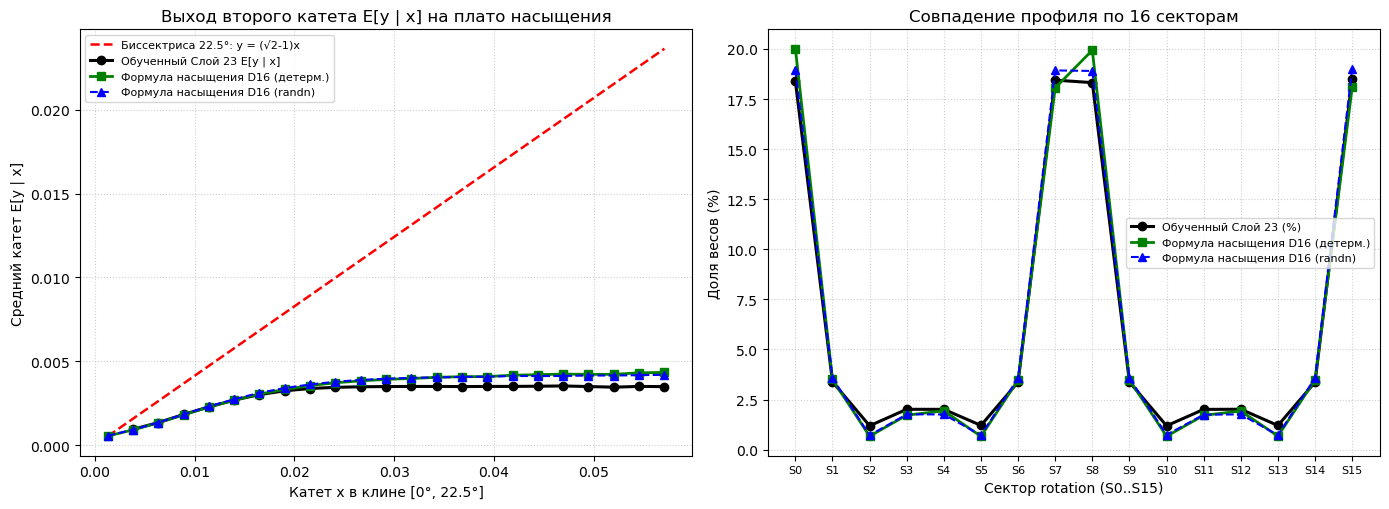

In [5]:
import math
import matplotlib.pyplot as plt
import numpy as np
import torch
from d16_complex import D16ComplexTensor, TAN_PI_8

# 1. Эталон: обученный Слой 23 из loaded_d16_model
w_trained = loaded_d16_model.model.layers[23].mlp.up_proj.weight.value().detach().cpu()
re_tr, im_tr = w_trained.to_xy()
re_tr, im_tr = re_tr.float(), im_tr.float()
x_tr, y_tr = w_trained.x.float(), w_trained.y.float()
active_mask = ~w_trained.is_zero()

# Исходная 1D-координата w1 и масштаб слоя sigma_w
w1 = torch.where(re_tr.abs() >= im_tr.abs(), re_tr, im_tr)
sigma_w = float(w1[active_mask].square().mean().sqrt().item())

# 2. ФОРМУЛА НАСЫЩЕНИЯ D16 (СВЯЗЬ С АКТИВАЦИЕЙ):
# w2(w1) = y_sat * (|w1| / (w0 + |w1|)) * xi
y_sat = 0.235 * sigma_w   # Потолок плато насыщения (~0.00355 на левом графике)
w0    = 0.145 * sigma_w   # Порог выхода на плато

# Детерминированная фаза xi из локального градиента соседних синапсов
dw = torch.roll(w1, -1, dims=-1) - torch.roll(w1, 1, dims=-1)
dw_std = float(dw[active_mask].square().mean().sqrt().item())
xi_det = dw / max(dw_std, 1e-8)

w2_sat_det = y_sat * (w1.abs() / (w0 + w1.abs())) * xi_det

# Для сравнения: Гипотеза 1 с тем же законом насыщения и случайной фазой N(0, 1)
torch.manual_seed(42)
w2_sat_rnd = y_sat * (w1.abs() / (w0 + w1.abs())) * torch.randn_like(w1)

# Упаковываем через стандартный конструктор D16ComplexTensor.pack
is_im_row = (im_tr.abs().mean(dim=-1, keepdim=True) > re_tr.abs().mean(dim=-1, keepdim=True))
z_sat_det = D16ComplexTensor.pack(
    torch.where(is_im_row, w2_sat_det, w1),
    torch.where(is_im_row, w1, w2_sat_det),
)
z_sat_rnd = D16ComplexTensor.pack(
    torch.where(is_im_row, w2_sat_rnd, w1),
    torch.where(is_im_row, w1, w2_sat_rnd),
)

# 3. Сводная таблица совпадения с эталоном
def _report_line(label: str, z: D16ComplexTensor, mask: torch.Tensor):
    yx = float((z.y.float()[mask] / z.x.float()[mask].clamp_min(1e-12)).mean().item())
    st = z.state()[mask]
    cnt = torch.bincount(st, minlength=18)[:16].float()
    cnt = cnt / cnt.sum().clamp_min(1.0) * 100.0
    diag = float(cnt[[1, 2, 5, 6, 9, 10, 13, 14]].sum().item())
    plateau = float(z.y.float()[mask & (z.x.float() > 0.025)].mean().item())
    print(
        f"{label:<36} | Клин y/x = {yx:.4f} | 45°-сект = {diag:5.1f}% | "
        f"S0={cnt[0]:4.1f}%, S1={cnt[1]:4.1f}% | Плато y={plateau:.5f}"
    )
    return cnt.numpy()

print("=" * 116)
c_tr  = _report_line("1. Обученный Слой 23 (эталон)", w_trained, active_mask)
c_det = _report_line("2. Формула насыщения D16 (детерм.)", z_sat_det, active_mask)
c_rnd = _report_line("3. Формула насыщения D16 (randn)", z_sat_rnd, active_mask)
print("=" * 116)

# 4. Графики: плато E[y | x] в клине и профиль 16 секторов
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

x_np = x_tr[active_mask].numpy()
max_x = float(np.percentile(x_np, 99.0))
bins = np.linspace(0.0, max_x, 24)
centers = 0.5 * (bins[:-1] + bins[1:])

def _curve(xv, yv):
    b_idx = np.digitize(xv, bins) - 1
    return np.array([yv[b_idx == b].mean() if np.any(b_idx == b) else np.nan for b in range(len(centers))])

ax1.plot(centers, centers * TAN_PI_8, "r--", lw=1.8, label="Биссектриса 22.5°: y = (√2-1)x")
ax1.plot(centers, _curve(x_np, y_tr[active_mask].numpy()), "ko-", lw=2.2, label="Обученный Слой 23 E[y | x]")
ax1.plot(centers, _curve(z_sat_det.x[active_mask].numpy(), z_sat_det.y[active_mask].numpy()), "gs-", lw=2.0, label="Формула насыщения D16 (детерм.)")
ax1.plot(centers, _curve(z_sat_rnd.x[active_mask].numpy(), z_sat_rnd.y[active_mask].numpy()), "b^--", lw=1.5, label="Формула насыщения D16 (randn)")
ax1.set_xlabel("Катет x в клине [0°, 22.5°]")
ax1.set_ylabel("Средний катет E[y | x]")
ax1.set_title("Выход второго катета E[y | x] на плато насыщения")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(fontsize=8)

sec = np.arange(16)
ax2.plot(sec, c_tr, "ko-", lw=2.2, label="Обученный Слой 23 (%)")
ax2.plot(sec, c_det, "gs-", lw=2.0, label="Формула насыщения D16 (детерм.)")
ax2.plot(sec, c_rnd, "b^--", lw=1.5, label="Формула насыщения D16 (randn)")
ax2.set_xticks(sec)
ax2.set_xticklabels([f"S{s}" for s in sec], fontsize=8)
ax2.set_xlabel("Сектор rotation (S0..S15)")
ax2.set_ylabel("Доля весов (%)")
ax2.set_title("Совпадение профиля по 16 секторам")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

Блок 15: Прямое соревнование Гипотезы 0 (w2 = 0), Гипотезы 1 (randn) и Гипотезы 2 (детерм. формула D16) при дообучении на GPU

In [12]:
import time
import matplotlib.pyplot as plt
import torch
from d16_adamw import D16AdamW
from d16_complex import D16ComplexTensor
from d16_qwen_importer import (
    D16QwenImportConfig,
    _fast_empty_d16_init,
    find_mlp_quartets,
    load_qwen_checkpoint,
)
from d16_qwen_model2 import D16Linear, D16QwenForCausalLM, encode_token_ids

# 1. Функция упаковки вещественного веса Qwen с вычислением второй координаты w2 = f(w1)
@torch.no_grad()
def pack_with_mode(
    w1: torch.Tensor,
    is_im_mask: torch.Tensor | None,
    im_dim: int,
    mode: str,
    *,
    c_sat: float = 0.205,
    c_w0: float = 0.120,
) -> D16ComplexTensor:
    if mode == "zero":
        w2 = torch.zeros_like(w1)
    else:
        wf = w1.to(torch.float32)
        sigma_w = wf.square().mean().sqrt().clamp_min(1e-8)
        envelope = (c_sat * sigma_w) * (wf.abs() / (c_w0 * sigma_w + wf.abs()))
        if mode == "d16_sat_rand":
            xi = torch.randn_like(wf)
        elif mode == "d16_sat_det":
            dw = torch.roll(wf, -1, dims=-1) - torch.roll(wf, 1, dims=-1) if wf.shape[-1] >= 3 else wf
            dw_std = dw.square().mean().sqrt().clamp_min(1e-8)
            idx_c = torch.arange(wf.shape[-1], device=wf.device)
            parity = (
                torch.where(((torch.arange(wf.shape[-2], device=wf.device).unsqueeze(-1) + idx_c) & 1) == 0, 1.0, -1.0)
                if wf.ndim >= 2
                else torch.where((idx_c & 1) == 0, 1.0, -1.0)
            )
            xi = (dw / dw_std) * parity
        else:
            raise ValueError(f"Unknown mode: {mode!r}")
        w2 = (envelope * xi).to(dtype=w1.dtype)

    if is_im_mask is None or not bool(is_im_mask.any()):
        return D16ComplexTensor.pack(w1, w2)
    mask = is_im_mask.to(device=w1.device, dtype=torch.bool)
    if w1.ndim == 2 and mask.ndim == 1:
        mask = mask.unsqueeze(1) if im_dim == 0 else mask.unsqueeze(0)
    return D16ComplexTensor.pack(torch.where(mask, w2, w1), torch.where(mask, w1, w2))

# 2. Загружаем чистый эталонный чекпоинт Qwen из QWEN_SOURCE (из Ячейки 1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
raw_sd, cfg_dict = load_qwen_checkpoint(QWEN_SOURCE, device="cpu")
sample_t = next(iter(raw_sd.values()))
target_dtype = sample_t.dtype

config = (
    D16QwenImportConfig.from_qwen_config(cfg_dict, indiff_eps="auto", indiff_rel=0.25)
    if cfg_dict is not None
    else D16QwenImportConfig.from_state_dict(raw_sd, indiff_eps="auto", indiff_rel=0.25)
)

with _fast_empty_d16_init(dtype=target_dtype, device=device):
    clean_model = D16QwenForCausalLM(config)
clean_model = clean_model.to(device)
D16Linear._MAX_WEIGHT_TILE = 1 << 26

# Находим маски Im-нейронов четвёрок по чистым весам Qwen (или берём из отчёта, так как они детерминированы)
im_masks = {}
for idx in range(config.num_hidden_layers):
    if "loaded_report" in globals() and loaded_report is not None and idx in loaded_report.layer_reports:
        im_masks[idx] = loaded_report.layer_reports[idx].is_im_neuron
    elif "import_report" in globals() and import_report is not None and idx in import_report.layer_reports:
        im_masks[idx] = import_report.layer_reports[idx].is_im_neuron
    else:
        p = f"model.layers.{idx}.mlp"
        rep = find_mlp_quartets(raw_sd[f"{p}.up_proj.weight"], raw_sd[f"{p}.gate_proj.weight"], raw_sd[f"{p}.down_proj.weight"], layer_idx=idx)
        im_masks[idx] = rep.is_im_neuron

@torch.no_grad()
def load_layer_from_raw(idx: int, mode: str):
    layer = clean_model.model.layers[idx]
    p = f"model.layers.{idx}"
    im_mask = im_masks[idx]
    layer.input_layernorm.gain.copy_(pack_with_mode(raw_sd[f"{p}.input_layernorm.weight"].to(device, target_dtype), None, 0, mode))
    layer.post_attention_layernorm.gain.copy_(pack_with_mode(raw_sd[f"{p}.post_attention_layernorm.weight"].to(device, target_dtype), None, 0, mode))
    for proj in ("q_proj", "k_proj", "v_proj", "o_proj"):
        pmod = getattr(layer.self_attn, proj)
        pmod.weight.copy_(pack_with_mode(raw_sd[f"{p}.self_attn.{proj}.weight"].to(device, target_dtype), None, 0, mode))
        if pmod.bias is not None:
            pmod.bias.copy_(pack_with_mode(raw_sd[f"{p}.self_attn.{proj}.bias"].to(device, target_dtype), None, 0, mode))
    layer.mlp.up_proj.weight.copy_(pack_with_mode(raw_sd[f"{p}.mlp.up_proj.weight"].to(device, target_dtype), im_mask, 0, mode))
    layer.mlp.gate_proj.weight.copy_(pack_with_mode(raw_sd[f"{p}.mlp.gate_proj.weight"].to(device, target_dtype), im_mask, 0, mode))
    layer.mlp.down_proj.weight.copy_(pack_with_mode(raw_sd[f"{p}.mlp.down_proj.weight"].to(device, target_dtype), im_mask, 1, mode))

# Инициализируем чистую базу всей модели (слои 0..21 и словарь embed_tokens) из raw_sd
with torch.no_grad():
    clean_model.model.embed_tokens.weight.copy_(
        pack_with_mode(raw_sd["model.embed_tokens.weight"].to(device, target_dtype), None, 0, "zero")
    )
    for idx in range(config.num_hidden_layers - 2):
        load_layer_from_raw(idx, "zero")

test_layer_indices = [config.num_hidden_layers - 2, config.num_hidden_layers - 1]

@torch.no_grad()
def reset_upper_layers_clean(mode: str):
    torch.manual_seed(42)
    clean_model.model.norm.gain.copy_(
        pack_with_mode(raw_sd["model.norm.weight"].to(device, target_dtype), None, 0, mode)
    )
    for idx in test_layer_indices:
        load_layer_from_raw(idx, mode)

# Размораживаем только тестируемые слои 22, 23 и финальный norm
for p in clean_model.parameters():
    p.requires_grad_(False)

trainable_d16 = []
for m_root in (clean_model.model.layers[-2], clean_model.model.layers[-1], clean_model.model.norm):
    for m in m_root.modules():
        if type(m).__name__ == "D16Parameter" and m not in trainable_d16:
            m.x.requires_grad_(True)
            m.y.requires_grad_(True)
            trainable_d16.append(m)

# Подготовка тестовой фразы
train_raw_ids = torch.tensor(
    [[785, 17047, 315, 6351, 5109, 304, 29728, 14155, 374, 1853, 71, 35520, 13]],
    dtype=torch.long,
)
train_d16_ids = encode_token_ids(train_raw_ids.to(device))

# 3. Чистое сравнение 3 способов генерации второй координаты w2 (12 шагов D16AdamW)
modes = [
    ("zero", "Базовый импорт (w2 = 0, на оси)"),
    ("d16_sat_rand", "Гипотеза 1: Насыщение D16 + randn"),
    ("d16_sat_det", "Гипотеза 2: Насыщение D16 (детерм.)"),
]
history = {}

print("=" * 112)
for mode_key, mode_label in modes:
    reset_upper_layers_clean(mode_key)
    opt = D16AdamW(trainable_d16, lr=3.0e-3, weight_decay=1e-4, indiff_eps="auto", indiff_rel=0.20)
    losses = []
    t0 = time.time()
    clean_model.train()
    for step in range(1, 13):
        opt.zero_grad()
        out = clean_model(input_ids=train_d16_ids, labels=train_d16_ids)
        l_val = float(out.loss.x.item())
        losses.append(l_val)
        out.loss.x.backward()
        opt.step(max_grad_norm=1.0)
    dt = time.time() - t0
    history[mode_key] = losses
    print(
        f"{mode_label:<38} | Старт Loss: {losses[0]:7.4f} -> Шаг 6: {losses[5]:7.4f} -> "
        f"Финал (Шаг 12): {losses[-1]:7.4f} | Время: {dt:.1f}с"
    )
print("=" * 112)

# 4. График сходимости Loss
plt.figure(figsize=(8.8, 4.8))
steps_x = range(1, 13)
plt.plot(steps_x, history["zero"], "ko--", lw=2.0, label="Базовый импорт: w2 = 0 (точки на оси y=0)")
plt.plot(steps_x, history["d16_sat_rand"], "b^-", lw=2.0, label="Гипотеза 1: Формула насыщения D16 (randn)")
plt.plot(steps_x, history["d16_sat_det"], "gs-", lw=2.2, label="Гипотеза 2: Формула насыщения D16 (детерм.)")
plt.xlabel("Шаг дообучения D16AdamW")
plt.ylabel("Loss (wedge_cross_entropy)")
plt.title("Чистое сравнение сходимости слоёв Qwen при разных способах задания 2-й координаты w2")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 458.69it/s]


AcceleratorError: CUDA error: out of memory
Search for `cudaErrorMemoryAllocation' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
